# CharmMining — Demo Chương 1 → Chương 3

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBrilliantCoder/frequent-itemset-mining/blob/main/notebooks/demo.ipynb)

Notebook tái lập **toàn bộ** dự án khai thác tập phổ biến đóng bằng thuật toán **CHARM** tự cài đặt bằng Julia:

| Phần | Nội dung |
|---|---|
| **0. Thiết lập** | Clone repo, cài Julia/Java, tải dữ liệu (kiểm tra SHA-256) |
| **1. Chương 1** | Chạy CHARM (bản cơ bản & tối ưu) trên CSDL mẫu, bộ kiểm thử tự động + đối chuẩn SPMF trên 5 benchmark |
| **2. Chương 2** | Thực nghiệm thời gian, số tập đóng, bộ nhớ và khả năng mở rộng: Basic vs. Optimized vs. SPMF |
| **3. Chương 3** | Ứng dụng 1 — Market Basket Analysis (UCI Online Retail); Ứng dụng 2 — Motif promoter E. coli (UCI Promoter Gene Sequences) |

Tất cả thực nghiệm chạy trên **toàn bộ** dữ liệu gốc (không lấy mẫu con). Cách chạy: **Runtime → Run all**.
Phần Chương 2 chạy lâu nhất vì mỗi điểm đo là một tiến trình riêng và chạy cả 3 cài đặt.

## 0. Thiết lập môi trường

Ô dưới đây clone repository (khi chạy trên Colab) và chuyển thư mục làm việc về gốc repo.

In [ ]:
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/TheBrilliantCoder/frequent-itemset-mining.git"
BRANCH = "main"
JULIA_VERSION = "1.13.2"

def find_repo_root():
    for candidate in (Path.cwd(), Path.cwd().parent):
        if (candidate / "src" / "CharmMining.jl").exists():
            return candidate
    return None

REPO_ROOT = find_repo_root()
if REPO_ROOT is None:
    target = Path("/content/frequent-itemset-mining")
    if not target.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(target)], check=True)
    REPO_ROOT = target
os.chdir(REPO_ROOT)
print("Working directory:", REPO_ROOT)
print(subprocess.check_output(["git", "log", "-1", "--oneline"], text=True).strip())

Working directory: /content/frequent-itemset-mining
11d6a17 Merge branch 'feat/dna-analysis' into fix/repo-cleanup


In [2]:
import shutil

def run(cmd, env=None):
    """Run a command, streaming its output into the notebook; fail the cell on error."""
    print("$", " ".join(cmd), flush=True)
    full_env = {**os.environ, **(env or {})}
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1, env=full_env)
    for line in proc.stdout:
        print(line, end="", flush=True)
    code = proc.wait()
    if code != 0:
        raise RuntimeError(f"Command failed with exit code {code}: {' '.join(cmd)}")

# Julia (pinned version, same as local experiments)
if shutil.which("julia") is None:
    minor = ".".join(JULIA_VERSION.split(".")[:2])
    url = f"https://julialang-s3.julialang.org/bin/linux/x64/{minor}/julia-{JULIA_VERSION}-linux-x86_64.tar.gz"
    run(["bash", "-c", f"curl -fsSL --retry 3 {url} -o /tmp/julia.tar.gz && "
         "mkdir -p /opt/julia && tar -xzf /tmp/julia.tar.gz -C /opt/julia --strip-components 1 && "
         "ln -sf /opt/julia/bin/julia /usr/local/bin/julia"])

# Java 25+ (tools/spmf.jar is compiled for Java 25, class-file version 69).
# Colab's preinstalled Java is older, so install Temurin 25 and put it first on PATH;
# the Julia scripts call `java` from PATH.
JAVA_MIN_MAJOR = 25

def java_major():
    if shutil.which("java") is None:
        return 0
    out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    version = out.split('"')[1] if '"' in out else "0"
    return int(version.split(".")[0])

if java_major() < JAVA_MIN_MAJOR:
    jdk_dir = "/opt/temurin-25"
    url = "https://api.adoptium.net/v3/binary/latest/25/ga/linux/x64/jre/hotspot/normal/eclipse"
    run(["bash", "-c", f"curl -fsSL --retry 3 -L {url} -o /tmp/jre25.tar.gz && "
         f"mkdir -p {jdk_dir} && tar -xzf /tmp/jre25.tar.gz -C {jdk_dir} --strip-components 1"])
    os.environ["JAVA_HOME"] = jdk_dir
    os.environ["PATH"] = f"{jdk_dir}/bin:" + os.environ["PATH"]
assert java_major() >= JAVA_MIN_MAJOR, "Java 25+ is required by tools/spmf.jar"

run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"])
run(["julia", "--project=.", "-e", "using Pkg; Pkg.instantiate(); Pkg.precompile()"])
run(["julia", "--version"])
run(["java", "-version"])

$ bash -c curl -fsSL --retry 3 -L https://api.adoptium.net/v3/binary/latest/25/ga/linux/x64/jre/hotspot/normal/eclipse -o /tmp/jre25.tar.gz && mkdir -p /opt/temurin-25 && tar -xzf /tmp/jre25.tar.gz -C /opt/temurin-25 --strip-components 1
$ /usr/bin/python3 -m pip install -q -r requirements.txt
$ julia --project=. -e using Pkg; Pkg.instantiate(); Pkg.precompile()
     Project No packages added to or removed from `/content/frequent-itemset-mining/Project.toml`
    Manifest No packages added to or removed from `/content/frequent-itemset-mining/Manifest.toml`
Precompiling packages...
   1090.2 ms  ✓ CharmMining
  1 dependency successfully precompiled in 1 seconds
$ julia --version
julia version 1.12.6
$ java -version
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../j

### Tải dữ liệu

`scripts/download_data.py` tải 5 benchmark FIMI (`chess`, `mushrooms`, `retail`, `T10I4D100K`, `accidents`), `spmf.jar`
và tập UCI Online Retail từ kho dữ liệu Hugging Face của nhóm, rồi **kiểm tra SHA-256** của từng file để bảo đảm dùng đúng dữ liệu
như khi chạy cục bộ. Tập DNA (`data/applications/dna/promoters.data`) có sẵn trong repository.

In [3]:
run([sys.executable, "scripts/download_data.py"])

$ /usr/bin/python3 scripts/download_data.py
Data mirror: https://huggingface.co/datasets/TheBrilliantCoder/frequent-itemset-mining-data
[download] data/benchmark/chess.txt (mirror, 342,294 bytes, sha256 verified)
[download] data/benchmark/mushrooms.txt (mirror, 603,491 bytes, sha256 verified)
[download] data/benchmark/retail.txt (mirror, 4,168,937 bytes, sha256 verified)
[download] data/benchmark/T10I4D100K.txt (mirror, 4,022,248 bytes, sha256 verified)
[download] data/benchmark/accidents.txt (mirror, 35,509,823 bytes, sha256 verified)
[download] tools/spmf.jar (mirror, 14,960,635 bytes, sha256 verified)
[download] data/applications/online_retail/Online Retail.xlsx (mirror, 23,715,344 bytes, sha256 verified)
All data files are present and verified.


## 1. Chương 1 — Thuật toán CHARM

### 1.1. Chạy thử trên CSDL mẫu Pasquier 1999
`run.jl` khai thác `data/toy/contextPasquier99.txt` với `minsup = 2` bằng bản tối ưu `mine_file_bit`
và ghi kết quả theo chuẩn SPMF (`<items> #SUP: <count>`).

In [4]:
run(["julia", "--project=.", "run.jl"])
print("\nInput (data/toy/contextPasquier99.txt):")
print(Path("data/toy/contextPasquier99.txt").read_text())
print("Closed itemsets (results/output.txt):")
print(Path("results/output.txt").read_text())

$ julia --project=. run.jl
Starting CHARM algorithm (Optimized)...
Found 9 closed itemsets.

Input (data/toy/contextPasquier99.txt):
1 2 5
2 4
2 3
1 2 4
1 3
2 3
1 3
1 2 3 5
1 2 3

Closed itemsets (results/output.txt):
2 #SUP: 7
1 #SUP: 6
3 #SUP: 6
1 2 #SUP: 4
1 3 #SUP: 4
2 3 #SUP: 4
1 2 3 #SUP: 2
1 2 5 #SUP: 2
2 4 #SUP: 2



### 1.2. Bộ kiểm thử tự động & đối chuẩn SPMF
`test/runtests.jl` chạy unit test cho cả bản cơ bản (`mine_file`) và bản tối ưu (`mine_file_bit`), module sinh luật,
rồi đối chiếu kết quả với SPMF `Charm_bitset` trên CSDL mẫu và **toàn bộ 5 benchmark**.

In [5]:
run(["julia", "--project=.", "test/runtests.jl"])

$ julia --project=. test/runtests.jl
           CHARMMINING.JL AUTOMATED TEST SUITE
 Julia Version : 1.12.6
 Platform      : x86_64-linux-gnu
 Active Threads: 1
 Started At    : 2026-11-27 16:05:31

[RUNNING] 1. Data Loading & Preprocessing (test_data.jl)
[PASSED]  1. Data Loading & Preprocessing (completed in 1.87s)

[RUNNING] 2. Itemset Ordering & Weights (test_ordering.jl)
[PASSED]  2. Itemset Ordering & Weights (completed in 0.19s)

[RUNNING] 3. CHARM Properties (1 to 4) (test_properties.jl)
[PASSED]  3. CHARM Properties (1 to 4) (completed in 0.25s)

[RUNNING] 4. Repository & Subsumption (test_repository.jl)
[PASSED]  4. Repository & Subsumption (completed in 1.11s)

[RUNNING] 5. CHARM Engine Integration (test_engine.jl)
[PASSED]  5. CHARM Engine Integration (completed in 1.14s)

[RUNNING] 6. Optimized CHARM (BitVector) (test_optimized.jl)
[PASSED]  6. Optimized CHARM (BitVector) (completed in 4.66s)

[RUNNING] 7. Association Rules (Closure) (test_rules.jl)
[PASSED]  7. Associatio

## 2. Chương 2 — Thực nghiệm & Đánh giá hiệu năng

Ba cài đặt được so sánh: **Basic** (`mine_file`, `BitSet`), **Optimized** (`mine_file_bit`, `BitVector` + `@simd`)
và **SPMF** `Charm_bitset` (Java). Mỗi lần chạy là một tiến trình riêng.

### 2.1. Thời gian chạy & số tập đóng theo `minsup`

In [6]:
import pandas as pd
from IPython.display import SVG, display

run(["julia", "--project=.", "comparison/compare_time.jl"])
time_df = pd.read_csv("comparison/time_result.csv")
time_df["itemsets_match"] = (time_df.julia_itemsets == time_df.spmf_itemsets) & (time_df.optimized_itemsets == time_df.spmf_itemsets)
display(time_df)
print("Số điểm đo khớp số tập đóng với SPMF:", int(time_df.itemsets_match.sum()), "/", len(time_df))

$ julia --project=. comparison/compare_time.jl
┌ Info: Benchmarking dataset
│   dataset = "chess"
└   path = "/content/frequent-itemset-mining/data/benchmark/chess.txt"
┌ Info: Completed benchmark point
│   dataset = "chess"
│   minsup_ratio = 0.9
│   minsup = 2877
│   julia_seconds = 7.473603511
│   optimized_seconds = 6.583008843
└   spmf_seconds = 1.023323498
┌ Info: Completed benchmark point
│   dataset = "chess"
│   minsup_ratio = 0.8
│   minsup = 2557
│   julia_seconds = 7.76947385
│   optimized_seconds = 6.436022416
└   spmf_seconds = 1.03735886
┌ Info: Completed benchmark point
│   dataset = "chess"
│   minsup_ratio = 0.7
│   minsup = 2238
│   julia_seconds = 8.563050493
│   optimized_seconds = 6.530946114
└   spmf_seconds = 2.75777411
┌ Info: Completed benchmark point
│   dataset = "chess"
│   minsup_ratio = 0.6
│   minsup = 1918
│   julia_seconds = 10.78723958
│   optimized_seconds = 8.429122559
└   spmf_seconds = 2.672296664
┌ Info: Completed benchmark point
│   dataset = "c

,dataset,dataset_type,minsup_ratio,minsup_count,julia_itemsets,optimized_itemsets,spmf_itemsets,julia_seconds,optimized_seconds,spmf_seconds,itemsets_match
0,chess,very dense,0.900,2877,498,498,498,7.473604,6.583009,1.023323,True
1,chess,very dense,0.800,2557,5083,5083,5083,7.769474,6.436022,1.037359,True
2,chess,very dense,0.700,2238,23892,23892,23892,8.563050,6.530946,2.757774,True
3,chess,very dense,0.600,1918,98392,98392,98392,10.787240,8.429123,2.672297,True
4,chess,very dense,0.500,1598,369450,369450,369450,28.452791,10.319014,7.390464,True
5,mushrooms,dense,0.800,6733,8,8,8,7.699119,6.604876,0.983532,True
6,mushrooms,dense,0.600,5050,19,19,19,7.701873,6.490783,1.024222,True
7,mushrooms,dense,0.500,4208,45,45,45,7.721109,6.444210,1.165607,True
8,mushrooms,dense,0.200,1684,1169,1169,1169,7.692139,6.820114,1.889279,True
9,mushrooms,dense,0.100,842,4850,4850,4850,7.048351,7.642394,1.297992,True


Số điểm đo khớp số tập đóng với SPMF: 31 / 31


$ julia --project=. comparison/plot_time.jl
Wrote /content/frequent-itemset-mining/comparison/plots/chess_runtime.svg
Wrote /content/frequent-itemset-mining/comparison/plots/chess_itemsets.svg
Wrote /content/frequent-itemset-mining/comparison/plots/mushrooms_runtime.svg
Wrote /content/frequent-itemset-mining/comparison/plots/mushrooms_itemsets.svg
Wrote /content/frequent-itemset-mining/comparison/plots/retail_runtime.svg
Wrote /content/frequent-itemset-mining/comparison/plots/retail_itemsets.svg
Wrote /content/frequent-itemset-mining/comparison/plots/T10I4D100K_runtime.svg
Wrote /content/frequent-itemset-mining/comparison/plots/T10I4D100K_itemsets.svg
Wrote /content/frequent-itemset-mining/comparison/plots/accidents_runtime.svg
Wrote /content/frequent-itemset-mining/comparison/plots/accidents_itemsets.svg
=== chess ===


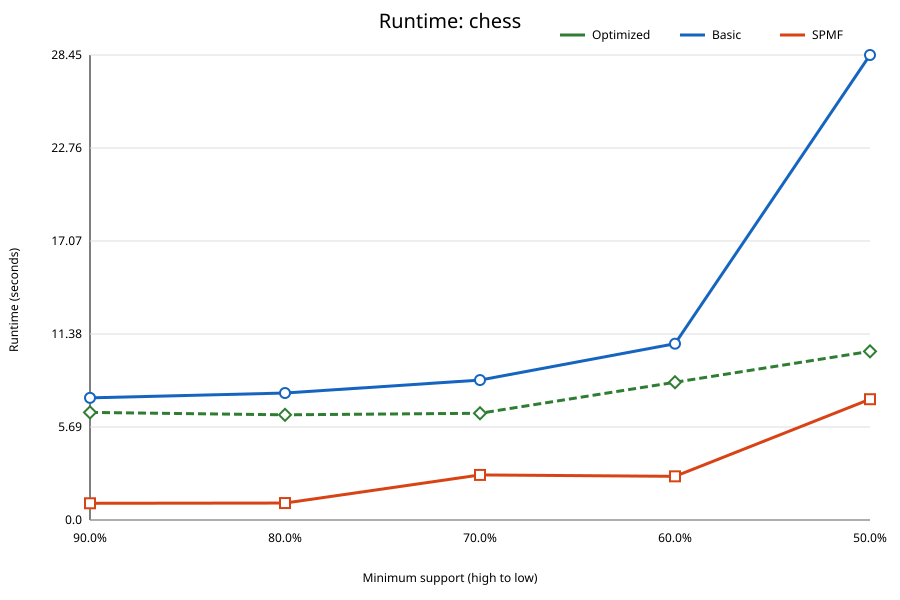

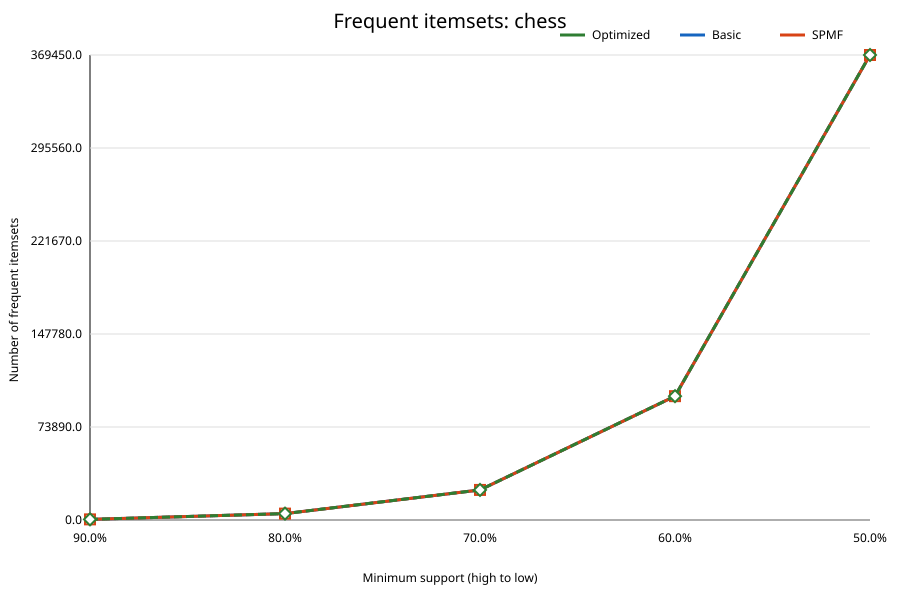

=== mushrooms ===


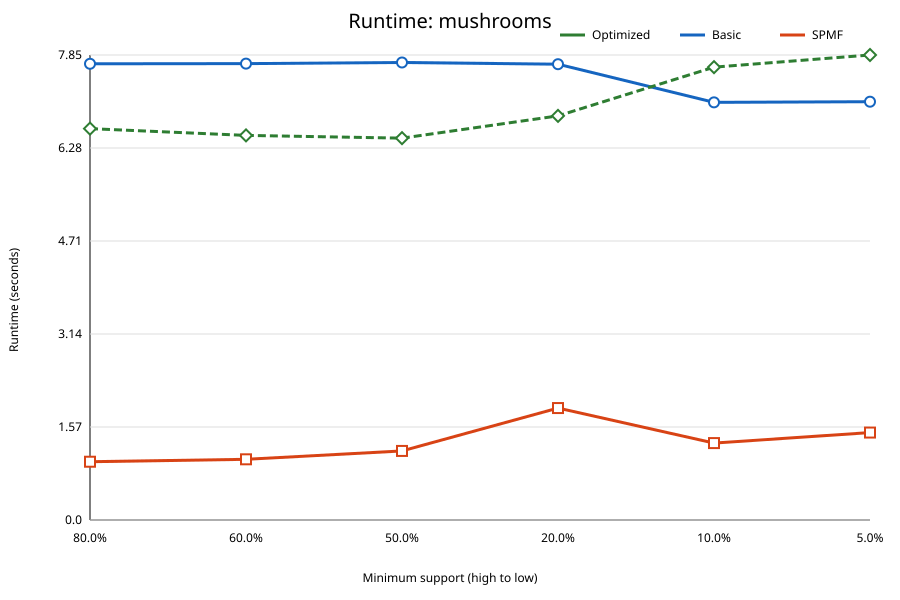

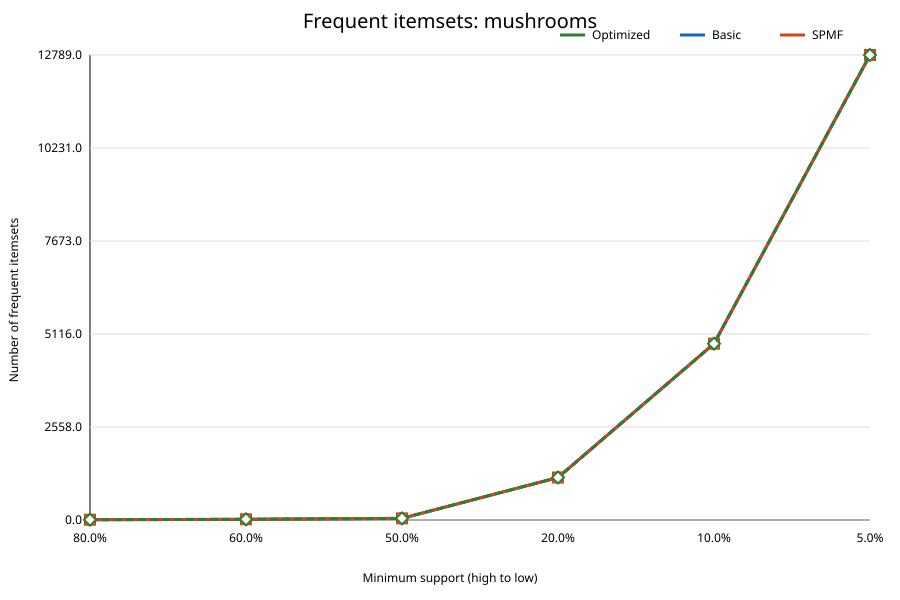

=== retail ===


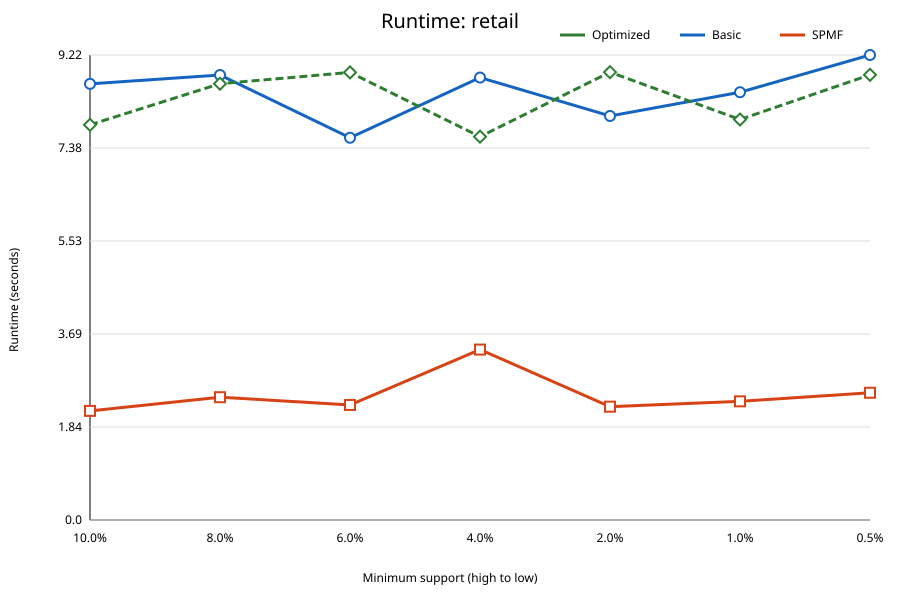

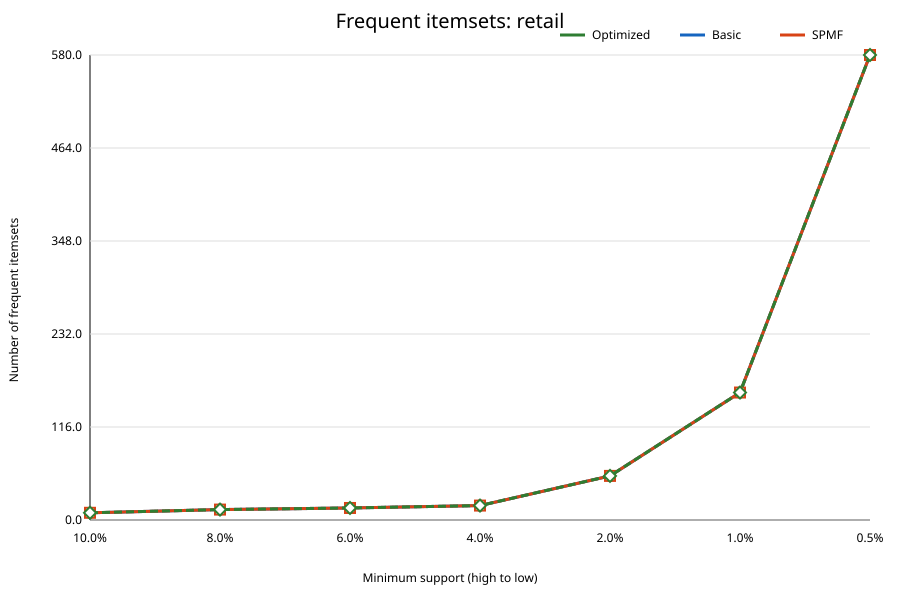

=== T10I4D100K ===


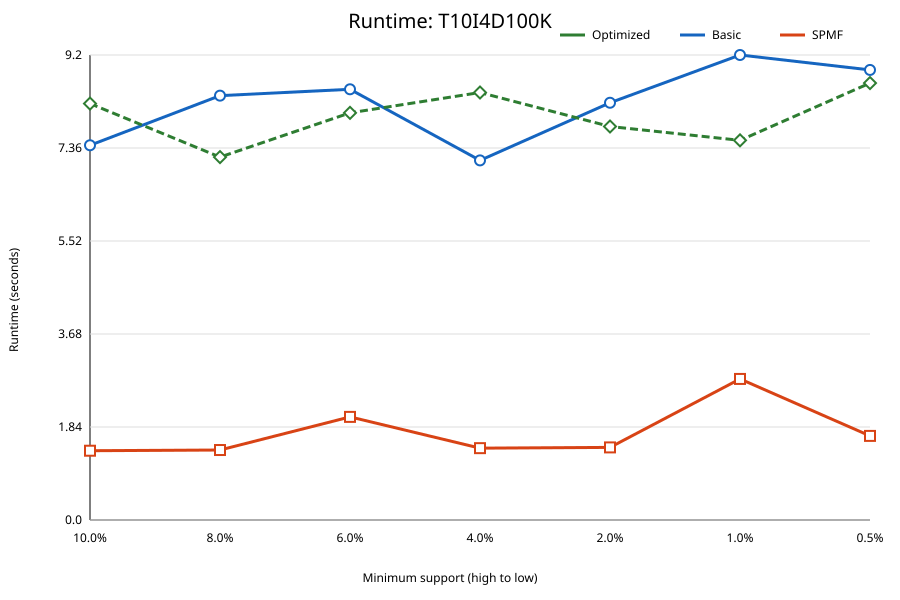

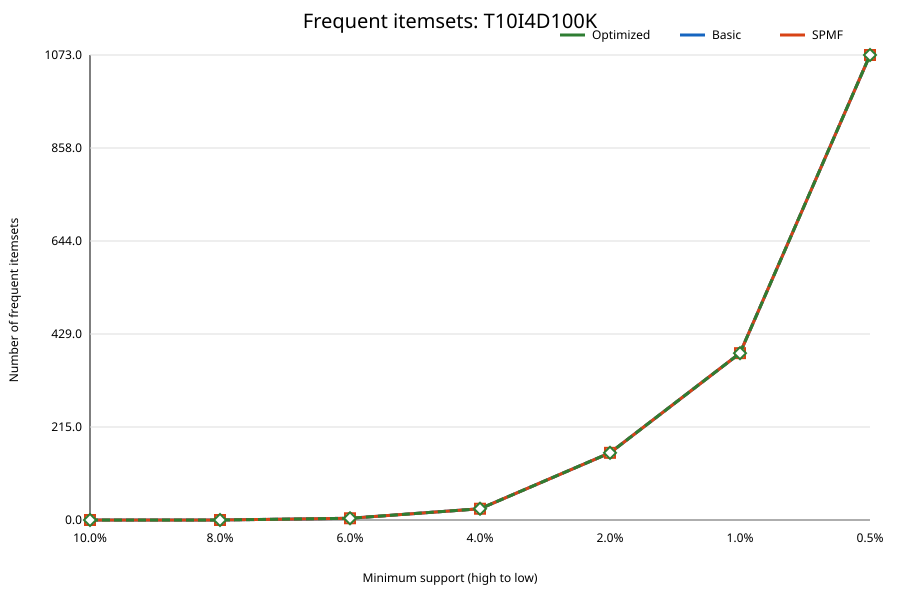

=== accidents ===


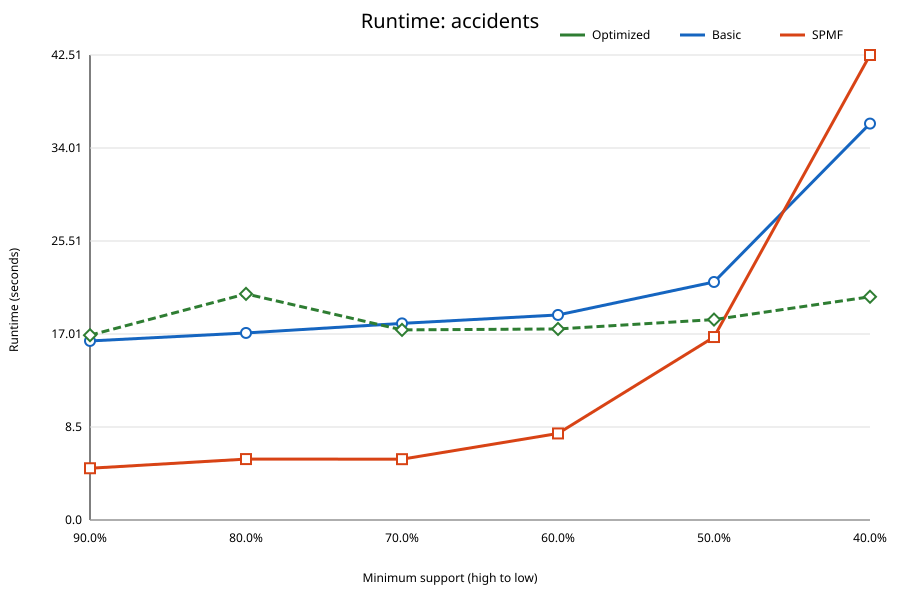

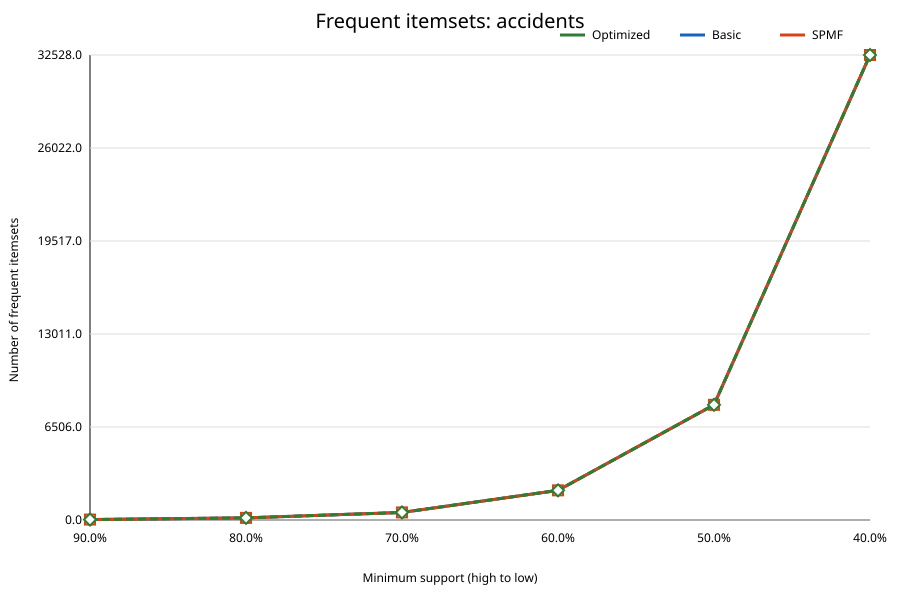

In [7]:
run(["julia", "--project=.", "comparison/plot_time.jl"])
for dataset in time_df.dataset.unique():
    print(f"=== {dataset} ===")
    display(SVG(filename=f"comparison/plots/{dataset}_runtime.svg"))
    display(SVG(filename=f"comparison/plots/{dataset}_itemsets.svg"))

### 2.2. Bộ nhớ đỉnh
Bộ nhớ đỉnh (RSS, `VmHWM`) của từng tiến trình; `net` là phần còn lại sau khi trừ chi phí khởi động Julia/JVM.

$ julia --project=. comparison/compare_memory.jl
Precompiling packages...
    920.2 ms  ✓ Statistics (serial)
  1 dependency successfully precompiled in 1 seconds
┌ Info: Baseline
│   impl = "basic"
└   peak_mb = 362.5
┌ Info: Baseline
│   impl = "optimized"
└   peak_mb = 362.7
┌ Info: Baseline
│   impl = "spmf"
└   peak_mb = 69.0
┌ Info: Dataset
│   name = "chess"
│   transactions = 3196
│   minsup_ratio = 0.65
└   minsup = 2078
┌ Info: Measured
│   name = "chess"
│   impl = "basic"
│   peak_mb = 456.5
└   net_mb = 94.0
┌ Info: Measured
│   name = "chess"
│   impl = "optimized"
│   peak_mb = 396.2
└   net_mb = 33.5
┌ Info: Measured
│   name = "chess"
│   impl = "spmf"
│   peak_mb = 126.5
└   net_mb = 57.5
┌ Info: Dataset
│   name = "mushrooms"
│   transactions = 8416
│   minsup_ratio = 0.35
└   minsup = 2946
┌ Info: Measured
│   name = "mushrooms"
│   impl = "basic"
│   peak_mb = 380.1
└   net_mb = 17.7
┌ Info: Measured
│   name = "mushrooms"
│   impl = "optimized"
│   peak_mb = 379.6

,dataset,minsup_ratio,minsup_count,implementation,median_peak_mb,median_net_mb,median_seconds,itemsets,net_reduction_vs_basic_pct
0,chess,0.65,2078,basic,456.54,94.05,10.108559,49034,NaN
1,chess,0.65,2078,optimized,396.17,33.46,8.292402,49034,64.43
2,chess,0.65,2078,spmf,126.52,57.52,1.925807,49034,38.84
3,mushrooms,0.35,2946,basic,380.14,17.65,8.251697,249,NaN
4,mushrooms,0.35,2946,optimized,379.57,16.86,7.911721,249,4.51
5,mushrooms,0.35,2946,spmf,76.93,7.92,1.047018,249,55.12
6,retail,0.04,3527,basic,544.99,182.50,8.894745,18,NaN
7,retail,0.04,3527,optimized,580.19,217.48,8.928964,18,-19.16
8,retail,0.04,3527,spmf,996.02,927.01,2.335256,18,-407.94
9,T10I4D100K,0.04,4000,basic,447.00,84.51,8.638656,26,NaN


$ julia --project=. comparison/plot_memory.jl
Wrote /content/frequent-itemset-mining/comparison/plots/memory_peak.svg
Wrote /content/frequent-itemset-mining/comparison/plots/memory_net.svg


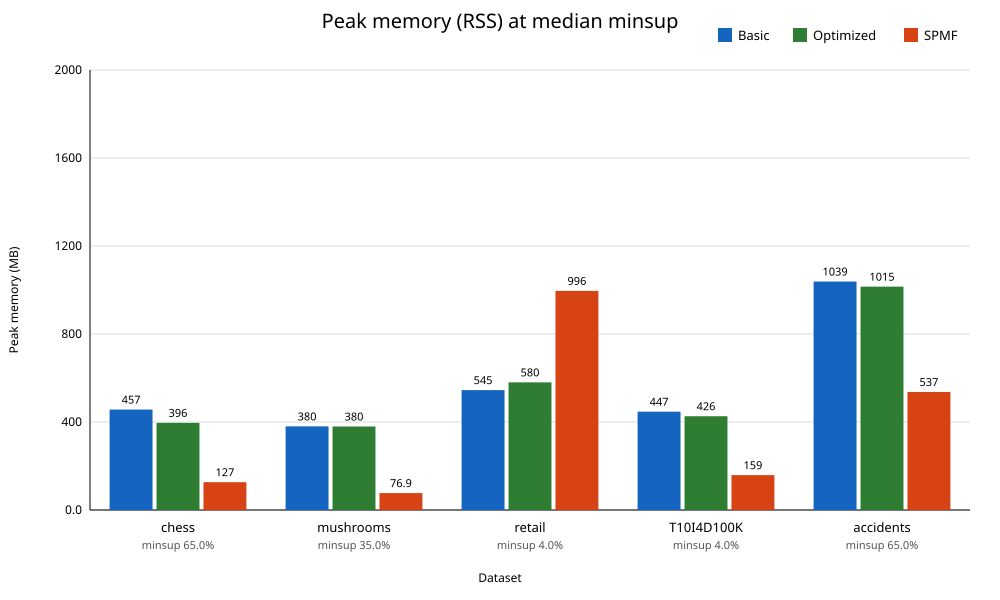

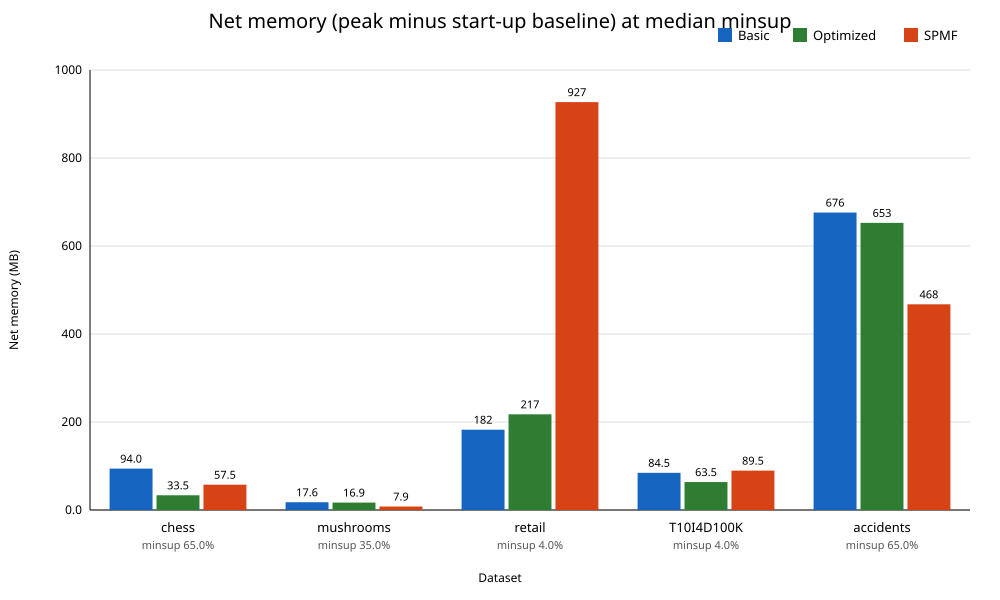

In [8]:
run(["julia", "--project=.", "comparison/compare_memory.jl"])
display(pd.read_csv("comparison/memory_summary.csv"))
run(["julia", "--project=.", "comparison/plot_memory.jl"])
display(SVG(filename="comparison/plots/memory_peak.svg"))
display(SVG(filename="comparison/plots/memory_net.svg"))

### 2.3. Khả năng mở rộng
CSDL được chia thành các tập con lồng nhau 10%, 25%, 50%, 75%, 100% (giữ `minsup` tương đối), đo thời gian ròng và bộ nhớ.

$ julia --project=. comparison/compare_scalability.jl
┌ Info: Dataset
│   DATASET = "T10I4D100K"
│   transactions = 100000
│   minsup_ratio = 0.01
│   seed = 42
└   runs = 3
┌ Info: Baseline
│   impl = "basic"
└   seconds = 8.326
┌ Info: Baseline
│   impl = "optimized"
└   seconds = 7.716
┌ Info: Baseline
│   impl = "spmf"
└   seconds = 0.645
┌ Info: Sub-database
│   percent = 10
│   transactions = 10000
└   minsup = 100
┌ Info: Measured
│   impl = "basic"
│   wall_seconds = 8.12
└   itemsets = 396
┌ Info: Measured
│   impl = "optimized"
│   wall_seconds = 7.619
└   itemsets = 396
┌ Info: Measured
│   impl = "spmf"
│   wall_seconds = 0.98
└   itemsets = 396
┌ Info: Sub-database
│   percent = 25
│   transactions = 25000
└   minsup = 250
┌ Info: Measured
│   impl = "basic"
│   wall_seconds = 11.341
└   itemsets = 390
┌ Info: Measured
│   impl = "optimized"
│   wall_seconds = 7.967
└   itemsets = 390
┌ Info: Measured
│   impl = "spmf"
│   wall_seconds = 1.34
└   itemsets = 390
┌ Info: Sub

,dataset,implementation,fraction,transactions,minsup_ratio,minsup_count,median_wall_seconds,baseline_seconds,net_seconds,median_peak_mb,itemsets
0,T10I4D100K,basic,0.10,10000,0.01,100,8.120377,8.325745,0.000000,393.77,396
1,T10I4D100K,optimized,0.10,10000,0.01,100,7.619251,7.716332,0.000000,367.97,396
2,T10I4D100K,spmf,0.10,10000,0.01,100,0.979538,0.644702,0.334836,80.49,396
3,T10I4D100K,basic,0.25,25000,0.01,250,11.340964,8.325745,3.015220,422.66,390
4,T10I4D100K,optimized,0.25,25000,0.01,250,7.966596,7.716332,0.250264,394.27,390
5,T10I4D100K,spmf,0.25,25000,0.01,250,1.340336,0.644702,0.695634,104.62,390
6,T10I4D100K,basic,0.50,50000,0.01,500,9.244014,8.325745,0.918269,426.22,385
7,T10I4D100K,optimized,0.50,50000,0.01,500,8.138759,7.716332,0.422426,395.41,385
8,T10I4D100K,spmf,0.50,50000,0.01,500,1.401228,0.644702,0.756527,123.06,385
9,T10I4D100K,basic,0.75,75000,0.01,750,9.173840,8.325745,0.848096,479.46,385


,dataset,implementation,power_exponent,r2_linear,r2_power,r2_exponential,time_ratio_100_vs_50,verdict
0,T10I4D100K,basic,2.6590,0.0000,0.5707,0.3250,1.471,polynomial (about O(n^2.66))
1,T10I4D100K,optimized,2.9339,0.9789,0.8595,0.6277,2.948,polynomial (about O(n^2.93))
2,T10I4D100K,spmf,0.4181,0.8091,0.8931,0.6995,1.274,sub-linear (about O(n^0.42))


$ julia --project=. comparison/plot_scalability.jl
Wrote /content/frequent-itemset-mining/comparison/plots/scalability_runtime.svg
Wrote /content/frequent-itemset-mining/comparison/plots/scalability_loglog.svg
Wrote /content/frequent-itemset-mining/comparison/plots/scalability_memory.svg


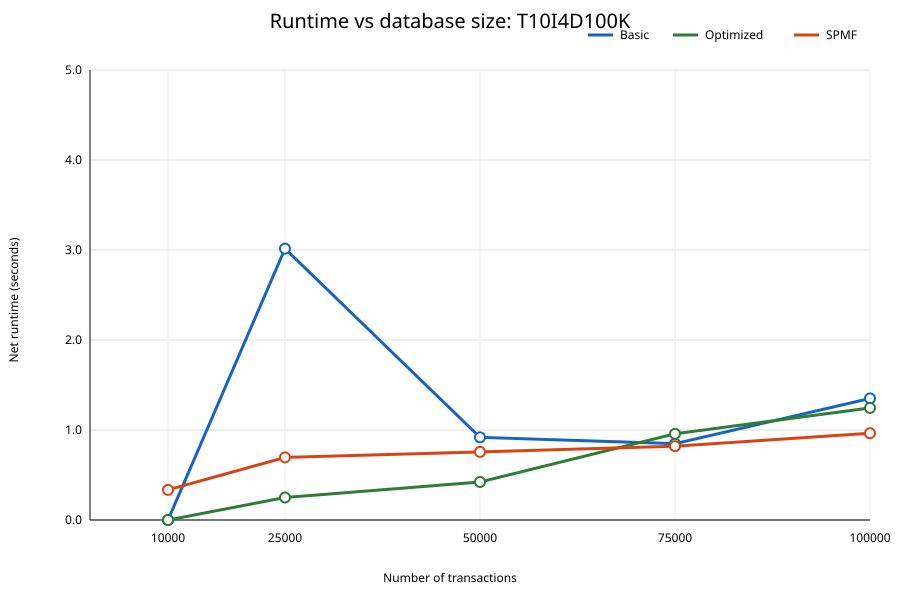

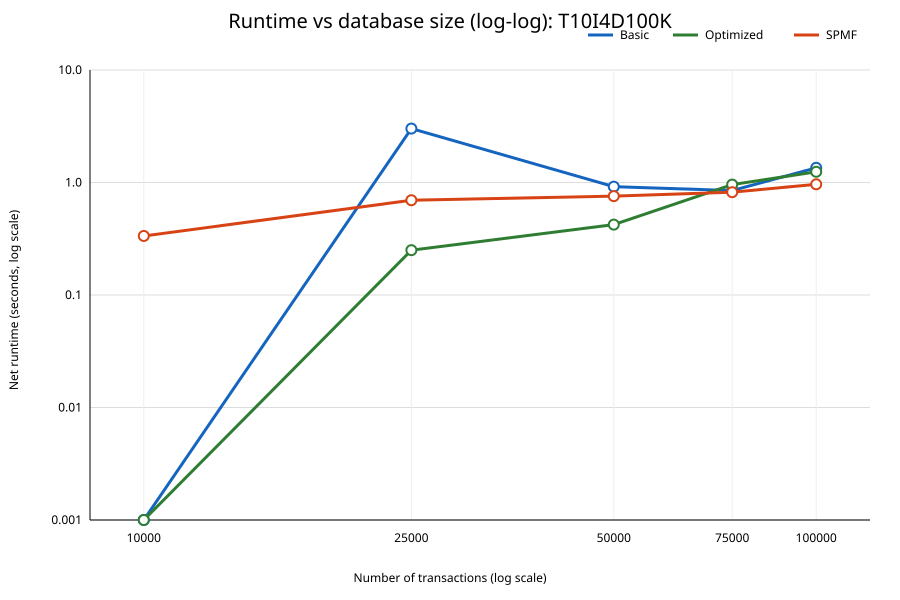

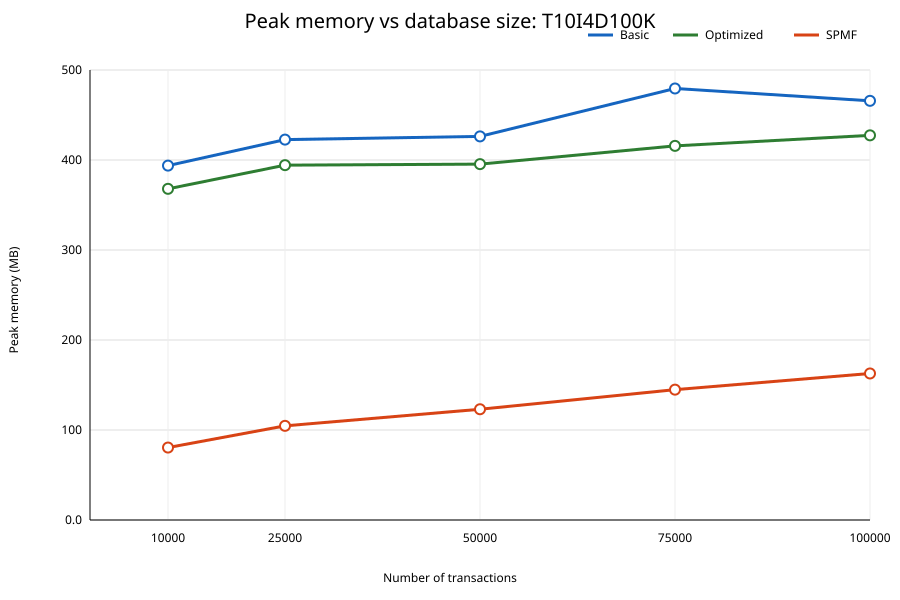

In [9]:
run(["julia", "--project=.", "comparison/compare_scalability.jl"])
display(pd.read_csv("comparison/scalability_summary.csv"))
display(pd.read_csv("comparison/scalability_analysis.csv"))
run(["julia", "--project=.", "comparison/plot_scalability.jl"])
for name in ["scalability_runtime", "scalability_loglog", "scalability_memory"]:
    display(SVG(filename=f"comparison/plots/{name}.svg"))

## 3. Chương 3 — Ứng dụng thực tế

### 3.1. Ứng dụng 1: Phân tích Giỏ hàng (Market Basket Analysis)

**Thuật toán sử dụng:** **Optimized CHARM** (`CharmMining.jl`, tự cài đặt từ đầu bằng Julia — Chương 1) kết hợp bộ sinh luật kết hợp dựa trên **bao đóng Galois (`ClosureSupportIndex`)** (`src/rules.jl`).

**Tập dữ liệu:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) (giao dịch bán lẻ trực tuyến tại Vương quốc Anh, 12/2010 – 12/2011, 541.909 dòng hóa đơn).

### Thiết kế biến đổi dữ liệu & Độ phù hợp với thuật toán CHARM
- Mỗi hóa đơn (`InvoiceNo`) sau khi loại bỏ đơn hủy, số lượng/giá âm và các mã phí dịch vụ (`POST`, `DOT`, `M`, `C2`, `CRUK`, `AMAZONFEE`, `GIFT_*`, ...) được gom thành một giao dịch gồm tập các mã sản phẩm (`StockCode`, chuẩn hóa viết hoa) duy nhất.
- Dữ liệu bán lẻ trực tuyến có đặc tính **rất thưa (sparse)** (3.787 SKU, mật độ ma trận **0.691%**), chứa nhiều cụm sản phẩm mua kèm chặt chẽ như bộ nhãn thảo mộc **Herb Marker**, bộ đĩa trà **Regency Tea Plate**, đồ trang trí Giáng sinh bằng gỗ, và nhà búp bê **Poppy's Playhouse**.
- Thuật toán **Optimized CHARM** biểu diễn `Tidset` bằng mảng bit liền kề (`BitVector`, 309 từ 64-bit ≈ 2.47 KB/item) cùng phép giao `@inbounds @simd`, chỉ mất trung vị **74.16 ms** tại `minsup = 1.0%`. Bộ sinh luật (`src/rules.jl`) tra cứu chính xác support của mọi tập con qua `ClosureSupportIndex` và sinh toàn bộ các luật có hợp $A \cup B$ là tập đóng (trên dữ liệu này tại `minsup = 1.0%`, cả 2.026 tập phổ biến đều tự đóng nên tập luật thu được trùng khớp 100% với toàn bộ tập luật phổ biến).

#### Tải, làm sạch và chuyển đổi dữ liệu sang định dạng SPMF
Script `applications/market_basket/prepare_data.py` thực hiện:
1. Tải bộ dữ liệu **UCI Online Retail** (nếu chưa có sẵn cục bộ).
2. Loại bỏ bản ghi thiếu `InvoiceNo`/`StockCode`/`Description`, đơn hủy (`InvoiceNo` bắt đầu bằng `'C'`), `Quantity <= 0`, `UnitPrice <= 0`, và các mã phí dịch vụ không phải hàng hóa (`POST`, `DOT`, `M`, `BANK CHARGES`, ...).
3. Chuẩn hóa tên sản phẩm theo `StockCode`, gán `item_id` nguyên liên tục `1..M` tất định.
4. Gom theo `InvoiceNo` và xuất `data/applications/online_retail/transactions.txt` (chuẩn SPMF) cùng từ điển `item_mapping.csv`.

In [10]:
import json
import pandas as pd

run([sys.executable, "applications/market_basket/prepare_data.py"])

with open("results/app1/dataset_summary.json", encoding="utf-8") as f:
    summary = json.load(f)

summary_rows = [
    ("Số dòng hóa đơn gốc (Raw rows)", f"{summary['raw_rows']:,}"),
    ("Loại bỏ thiếu InvoiceNo/StockCode/Description", f"{summary['dropped_missing_fields']:,}"),
    ("Loại bỏ đơn hàng bị hủy (InvoiceNo bắt đầu bằng 'C')", f"{summary['dropped_canceled_invoices']:,}"),
    ("Loại bỏ Quantity <= 0 hoặc UnitPrice <= 0", f"{summary['dropped_non_positive_qty_or_price']:,}"),
    ("Loại bỏ mã phí dịch vụ / không phải hàng hóa", f"{summary['dropped_non_product_items']:,}"),
    ("Số dòng sạch còn lại (Clean rows)", f"{summary['clean_rows']:,}"),
    ("Số giao dịch / hóa đơn (|D|)", f"{summary['n_transactions']:,}"),
    ("Số giao dịch có >= 2 sản phẩm", f"{summary['n_multi_item_transactions']:,}"),
    ("Số sản phẩm duy nhất (|I|)", f"{summary['n_unique_items']:,}"),
    ("Kích thước giỏ hàng (TB / Trung vị / Tối đa)", f"{summary['avg_basket_size']} / {summary['median_basket_size']} / {summary['max_basket_size']}"),
    ("Mật độ ma trận giao dịch", f"{summary['matrix_density'] * 100:.3f}%"),
]
display(pd.DataFrame(summary_rows, columns=["Chỉ số", "Giá trị"]))

$ /usr/bin/python3 applications/market_basket/prepare_data.py
Loading /content/frequent-itemset-mining/data/applications/online_retail/Online Retail.xlsx ...

=== Online Retail Data Preparation Complete ===
Raw rows            : 541,909
Clean rows          : 527,568
Transactions (|D|)  : 19,773 (multi-item: 18,267)
Unique items (|I|)  : 3,787
Avg / Median / Max  : 26.15 / 15 / 1105
Matrix density      : 0.691%
SPMF transactions   : /content/frequent-itemset-mining/data/applications/online_retail/transactions.txt
Item mapping        : /content/frequent-itemset-mining/data/applications/online_retail/item_mapping.csv
Summary JSON        : /content/frequent-itemset-mining/results/app1/dataset_summary.json


,Chỉ số,Giá trị
0,Số dòng hóa đơn gốc (Raw rows),"541,909"
1,Loại bỏ thiếu InvoiceNo/StockCode/Description,"1,454"
2,Loại bỏ đơn hàng bị hủy (InvoiceNo bắt đầu bằn...,"9,288"
3,Loại bỏ Quantity <= 0 hoặc UnitPrice <= 0,"1,063"
4,Loại bỏ mã phí dịch vụ / không phải hàng hóa,"2,536"
5,Số dòng sạch còn lại (Clean rows),"527,568"
6,Số giao dịch / hóa đơn (|D|),"19,773"
7,Số giao dịch có >= 2 sản phẩm,"18,267"
8,Số sản phẩm duy nhất (|I|),"3,787"
9,Kích thước giỏ hàng (TB / Trung vị / Tối đa),26.15 / 15 / 1105


#### Khai thác Tập phổ biến đóng & Sinh Luật kết hợp bằng `CharmMining.jl`
Toàn bộ kết quả được tạo trực tiếp bởi cài đặt **Optimized CHARM (`mine_file_bit`)** và module sinh luật kết hợp theo bao đóng (`generate_rules`, `top_rules_by_lift`) trong `src/rules.jl` — **không sử dụng bất kỳ thư viện FIM bên ngoài nào**.

In [11]:
run(["julia", "--project=.", "applications/market_basket/run_mba.jl"])

$ julia --project=. applications/market_basket/run_mba.jl
Loading transactions and product mapping...
Loaded 19773 transactions, 3787 unique items.

=== 1. Minsup Sensitivity Analysis (Optimized CHARM, median of 5 runs) ===
minsup(%)  minsup(#)  Closed(#)  AllFI(#)   MaxLen     Rules(c>=50%) Median(ms)  
5.00       989        36         36         1          0            0.39        
3.00       594        143        143        2          14           2.97        
2.50       495        234        234        3          40           6.41        
2.00       396        395        395        3          61           15.33       
1.50       297        763        763        4          215          41.69       
1.00       198        2026       2026       5          962          138.85      
0.80       159        3804       3804       5          2882         222.64      

=== 2. Primary Mining (minsup = 1.0% = 198 txs, minconf = 50.0%) ===
Found 2026 closed itemsets (1197 with size >= 2) in 451.6

#### Phân tích kết quả: Độ nhạy theo `minsup` & Top-10 Luật kết hợp theo Lift

In [12]:
sens_df = pd.read_csv("results/app1/minsup_sensitivity.csv")
print("=== Bảng độ nhạy theo ngưỡng minsup ===")
display(sens_df)

top10_df = pd.read_csv("results/app1/top10_rules_lift_dedup.csv")
print("\n=== Top-10 Luật kết hợp theo Lift (minsup = 1.0%, minconf = 50%, đã khử cặp đối xứng) ===")
display(top10_df[["rank", "antecedent_names", "consequent_names", "support_count", "support_pct", "confidence_pct", "lift", "leverage"]])

=== Bảng độ nhạy theo ngưỡng minsup ===


,minsup_pct,minsup_count,num_closed_itemsets,num_all_frequent_itemsets,compression_ratio,num_closed_len2plus,max_itemset_len,num_rules_conf50,runtime_ms
0,5.0,989,36,36,1.0,0,1,0,0.394
1,3.0,594,143,143,1.0,10,2,14,2.974
2,2.5,495,234,234,1.0,43,3,40,6.410
3,2.0,396,395,395,1.0,93,3,61,15.327
4,1.5,297,763,763,1.0,282,4,215,41.686
5,1.0,198,2026,2026,1.0,1197,5,962,138.846
6,0.8,159,3804,3804,1.0,2772,5,2882,222.636



=== Top-10 Luật kết hợp theo Lift (minsup = 1.0%, minconf = 50%, đã khử cặp đối xứng) ===


,rank,antecedent_names,consequent_names,support_count,support_pct,confidence_pct,lift,leverage
0,1,HERB MARKER ROSEMARY + HERB MARKER PARSLEY,HERB MARKER THYME,203,1.0267,94.42,78.7738,0.010136
1,2,HERB MARKER THYME + HERB MARKER PARSLEY,HERB MARKER ROSEMARY,203,1.0267,95.31,78.5195,0.010136
2,3,HERB MARKER THYME + HERB MARKER BASIL,HERB MARKER ROSEMARY,200,1.0115,95.24,78.4643,0.009986
3,4,HERB MARKER ROSEMARY + HERB MARKER BASIL,HERB MARKER THYME,200,1.0115,93.46,77.9723,0.009985
4,5,HERB MARKER THYME,HERB MARKER ROSEMARY,221,1.1177,93.25,76.8255,0.011031
5,6,HERB MARKER THYME + HERB MARKER ROSEMARY,HERB MARKER PARSLEY,203,1.0267,91.86,76.3131,0.010132
6,7,HERB MARKER THYME,HERB MARKER PARSLEY,213,1.0772,89.87,74.6667,0.010628
7,8,HERB MARKER PARSLEY,HERB MARKER ROSEMARY,215,1.0873,90.34,74.4257,0.010727
8,9,HERB MARKER THYME + HERB MARKER ROSEMARY,HERB MARKER BASIL,200,1.0115,90.50,73.9426,0.009978
9,10,HERB MARKER PARSLEY,HERB MARKER MINT,212,1.0722,89.08,73.3872,0.010576


#### Trực quan hóa kết quả

$ /usr/bin/python3 applications/market_basket/plot_mba.py
Saved /content/frequent-itemset-mining/results/app1/figures/fig1_top15_products.png
Saved /content/frequent-itemset-mining/results/app1/figures/fig2_minsup_sensitivity.png
Saved /content/frequent-itemset-mining/results/app1/figures/fig3_rules_scatter.png
Saved /content/frequent-itemset-mining/results/app1/figures/fig4_top10_lift.png


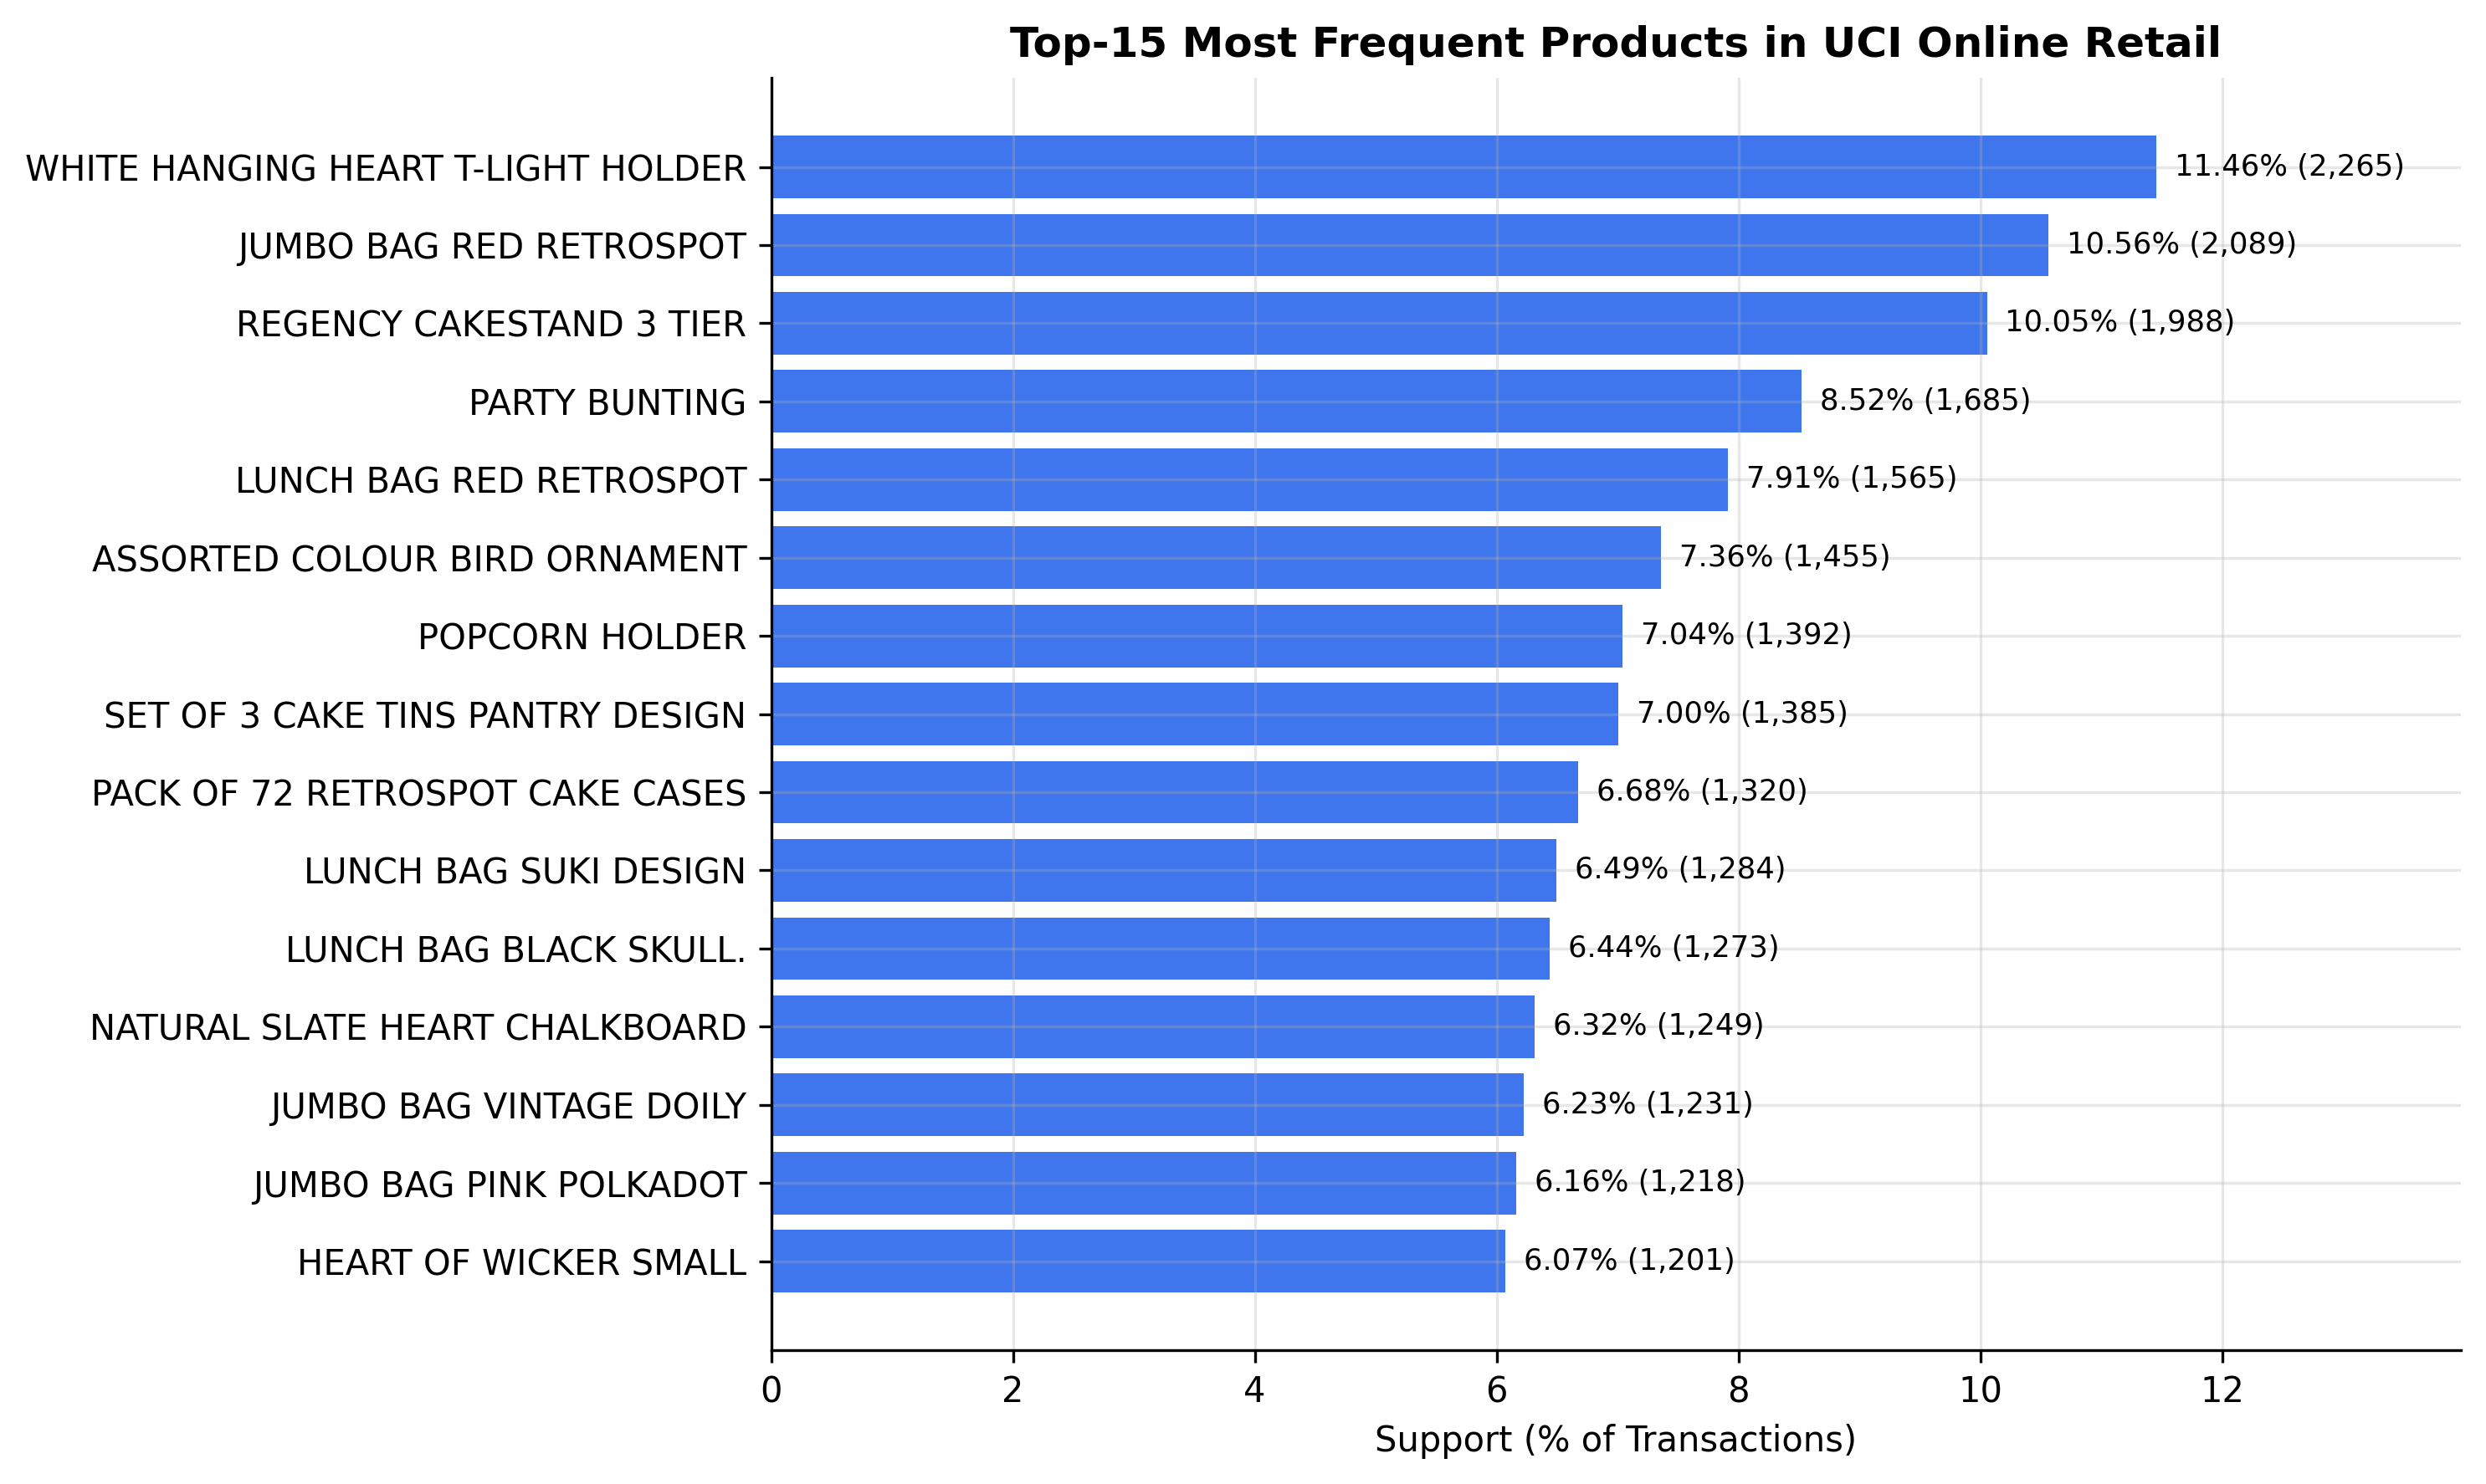

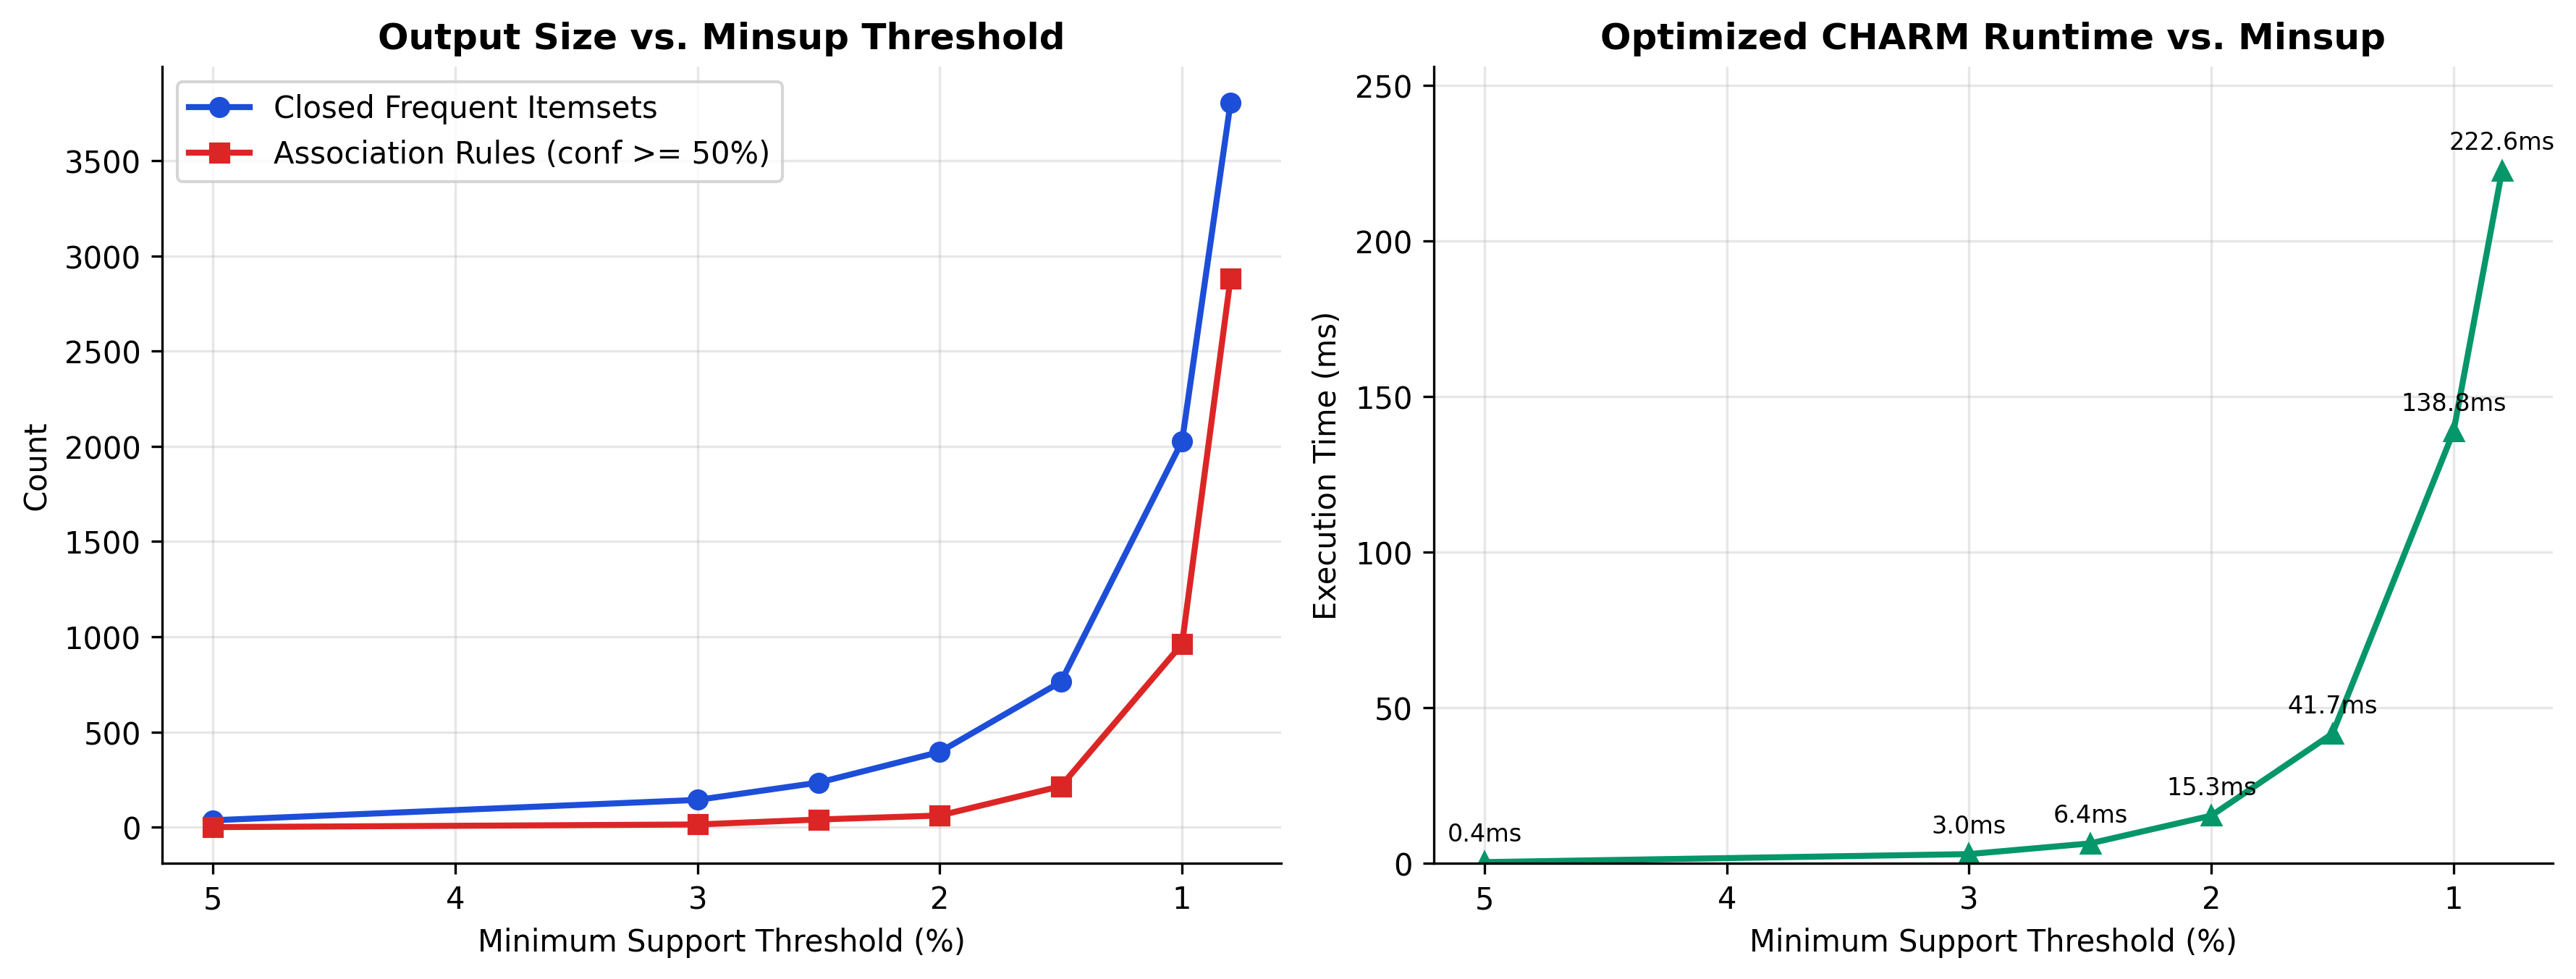

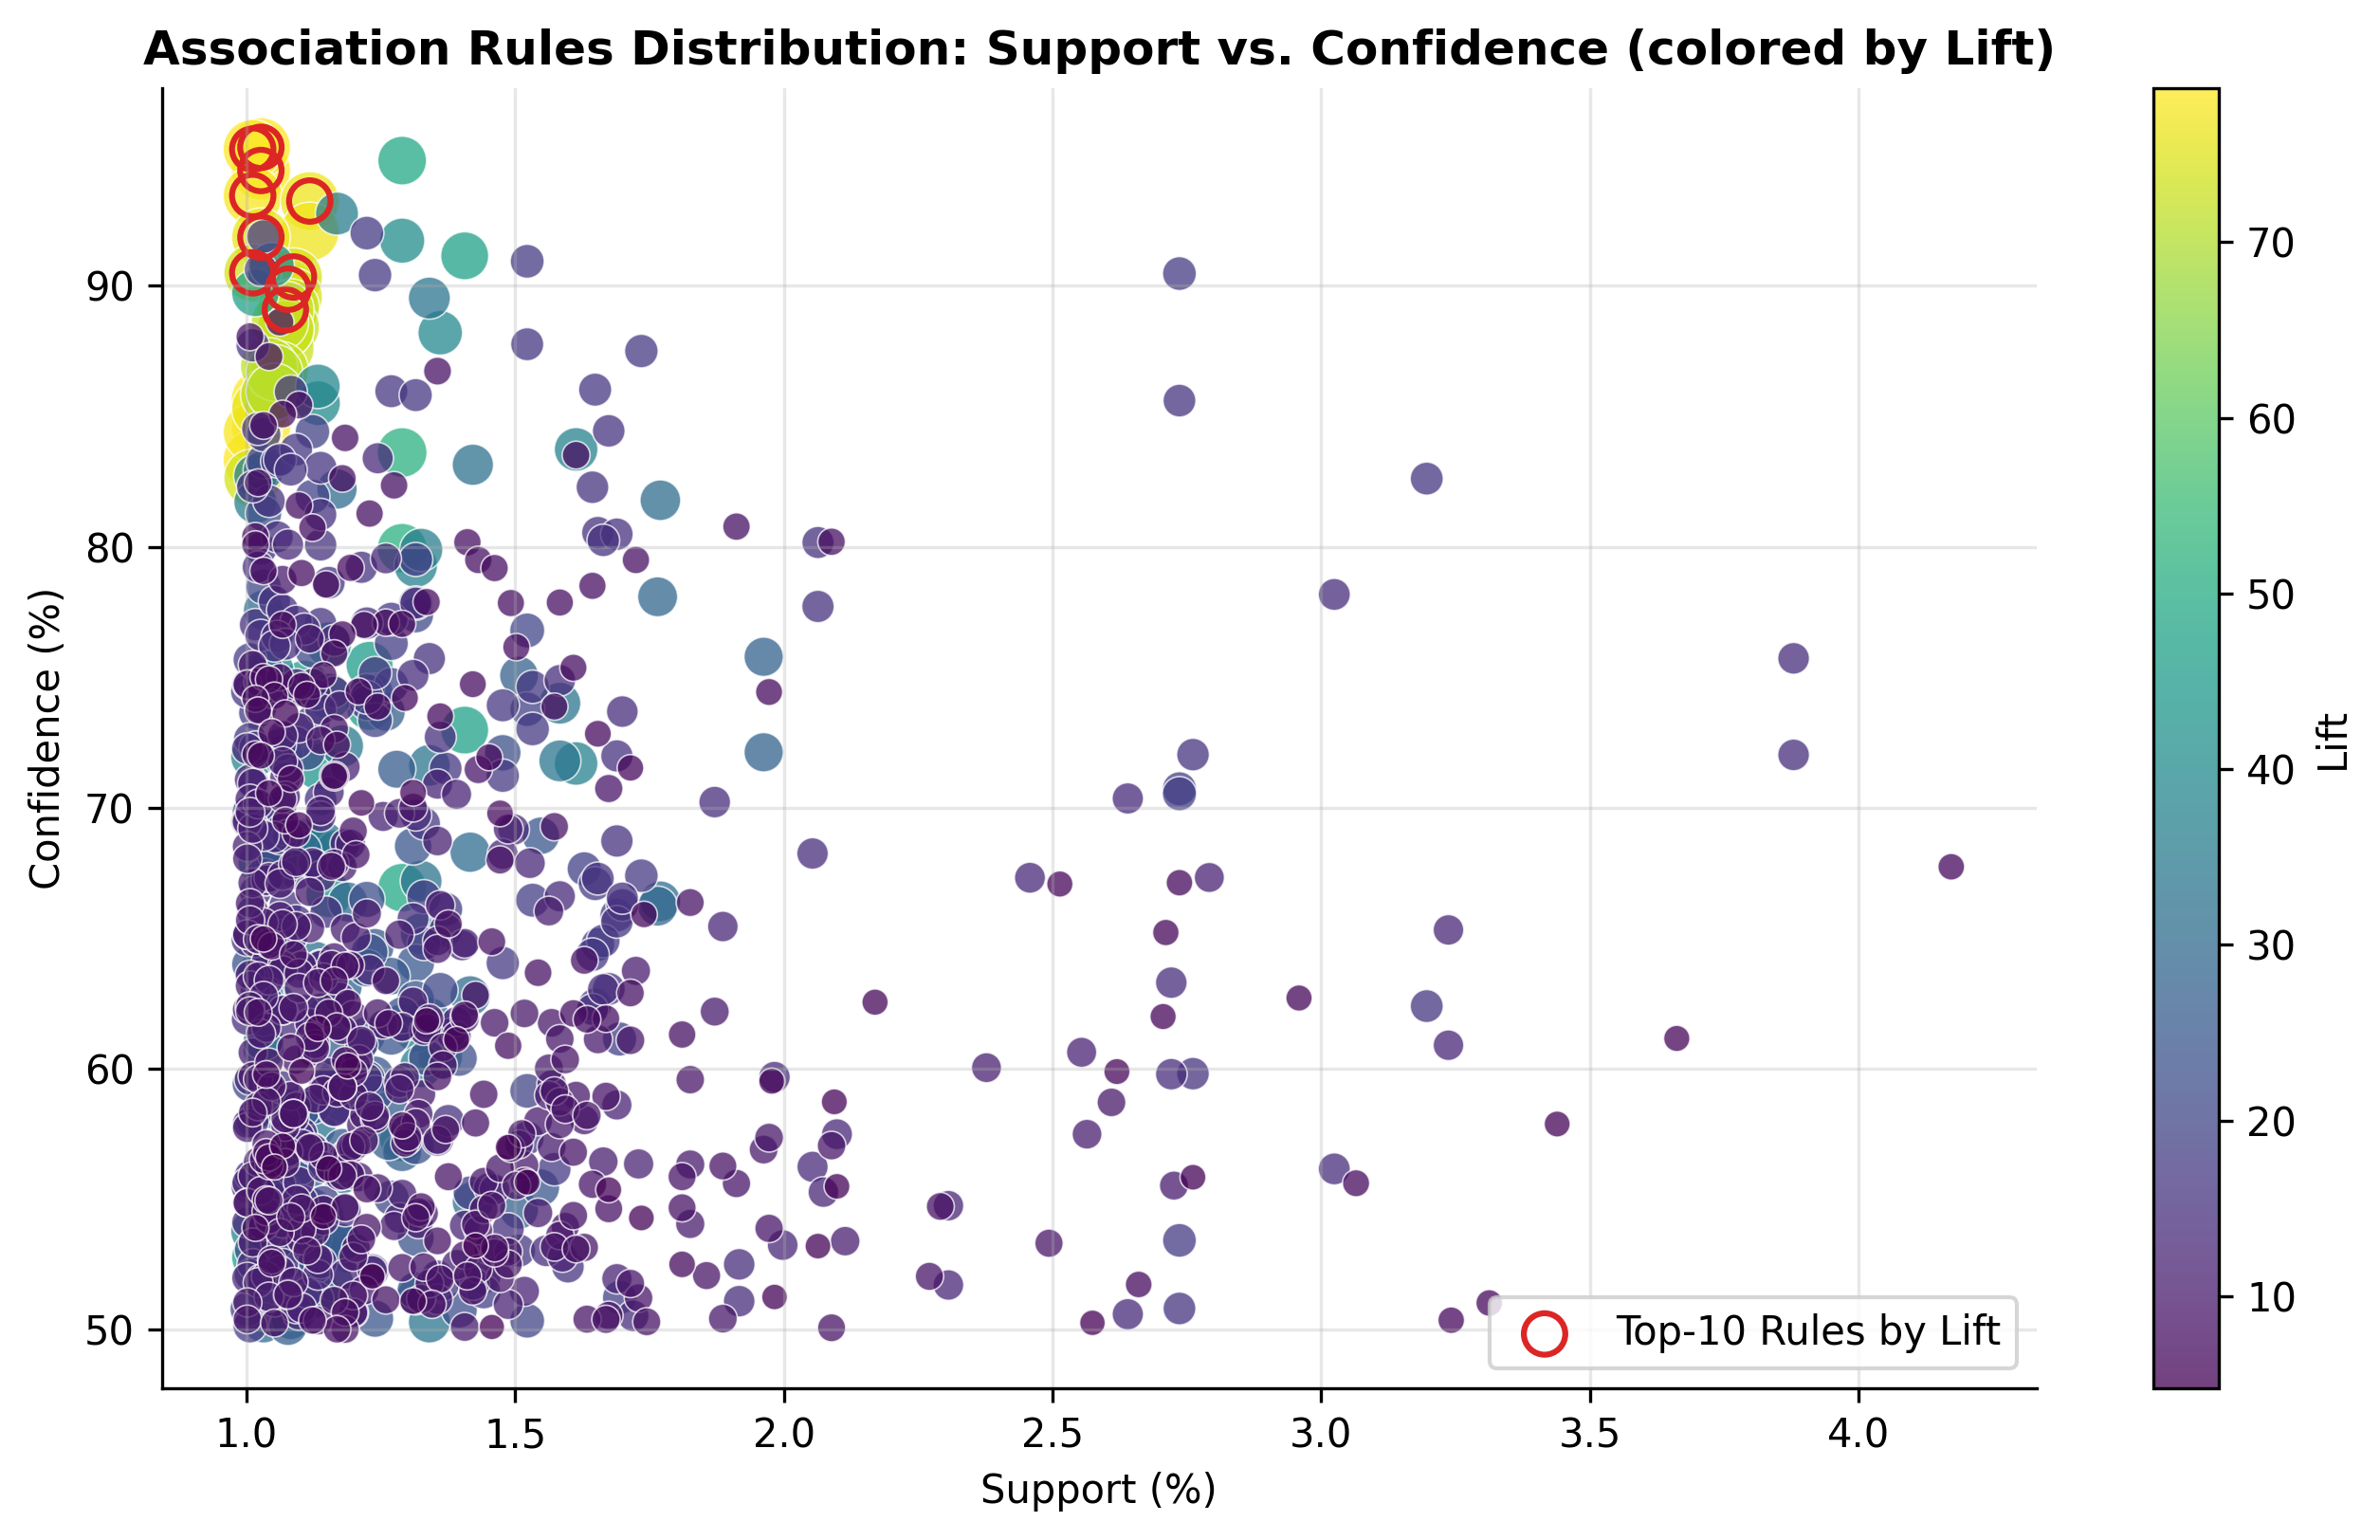

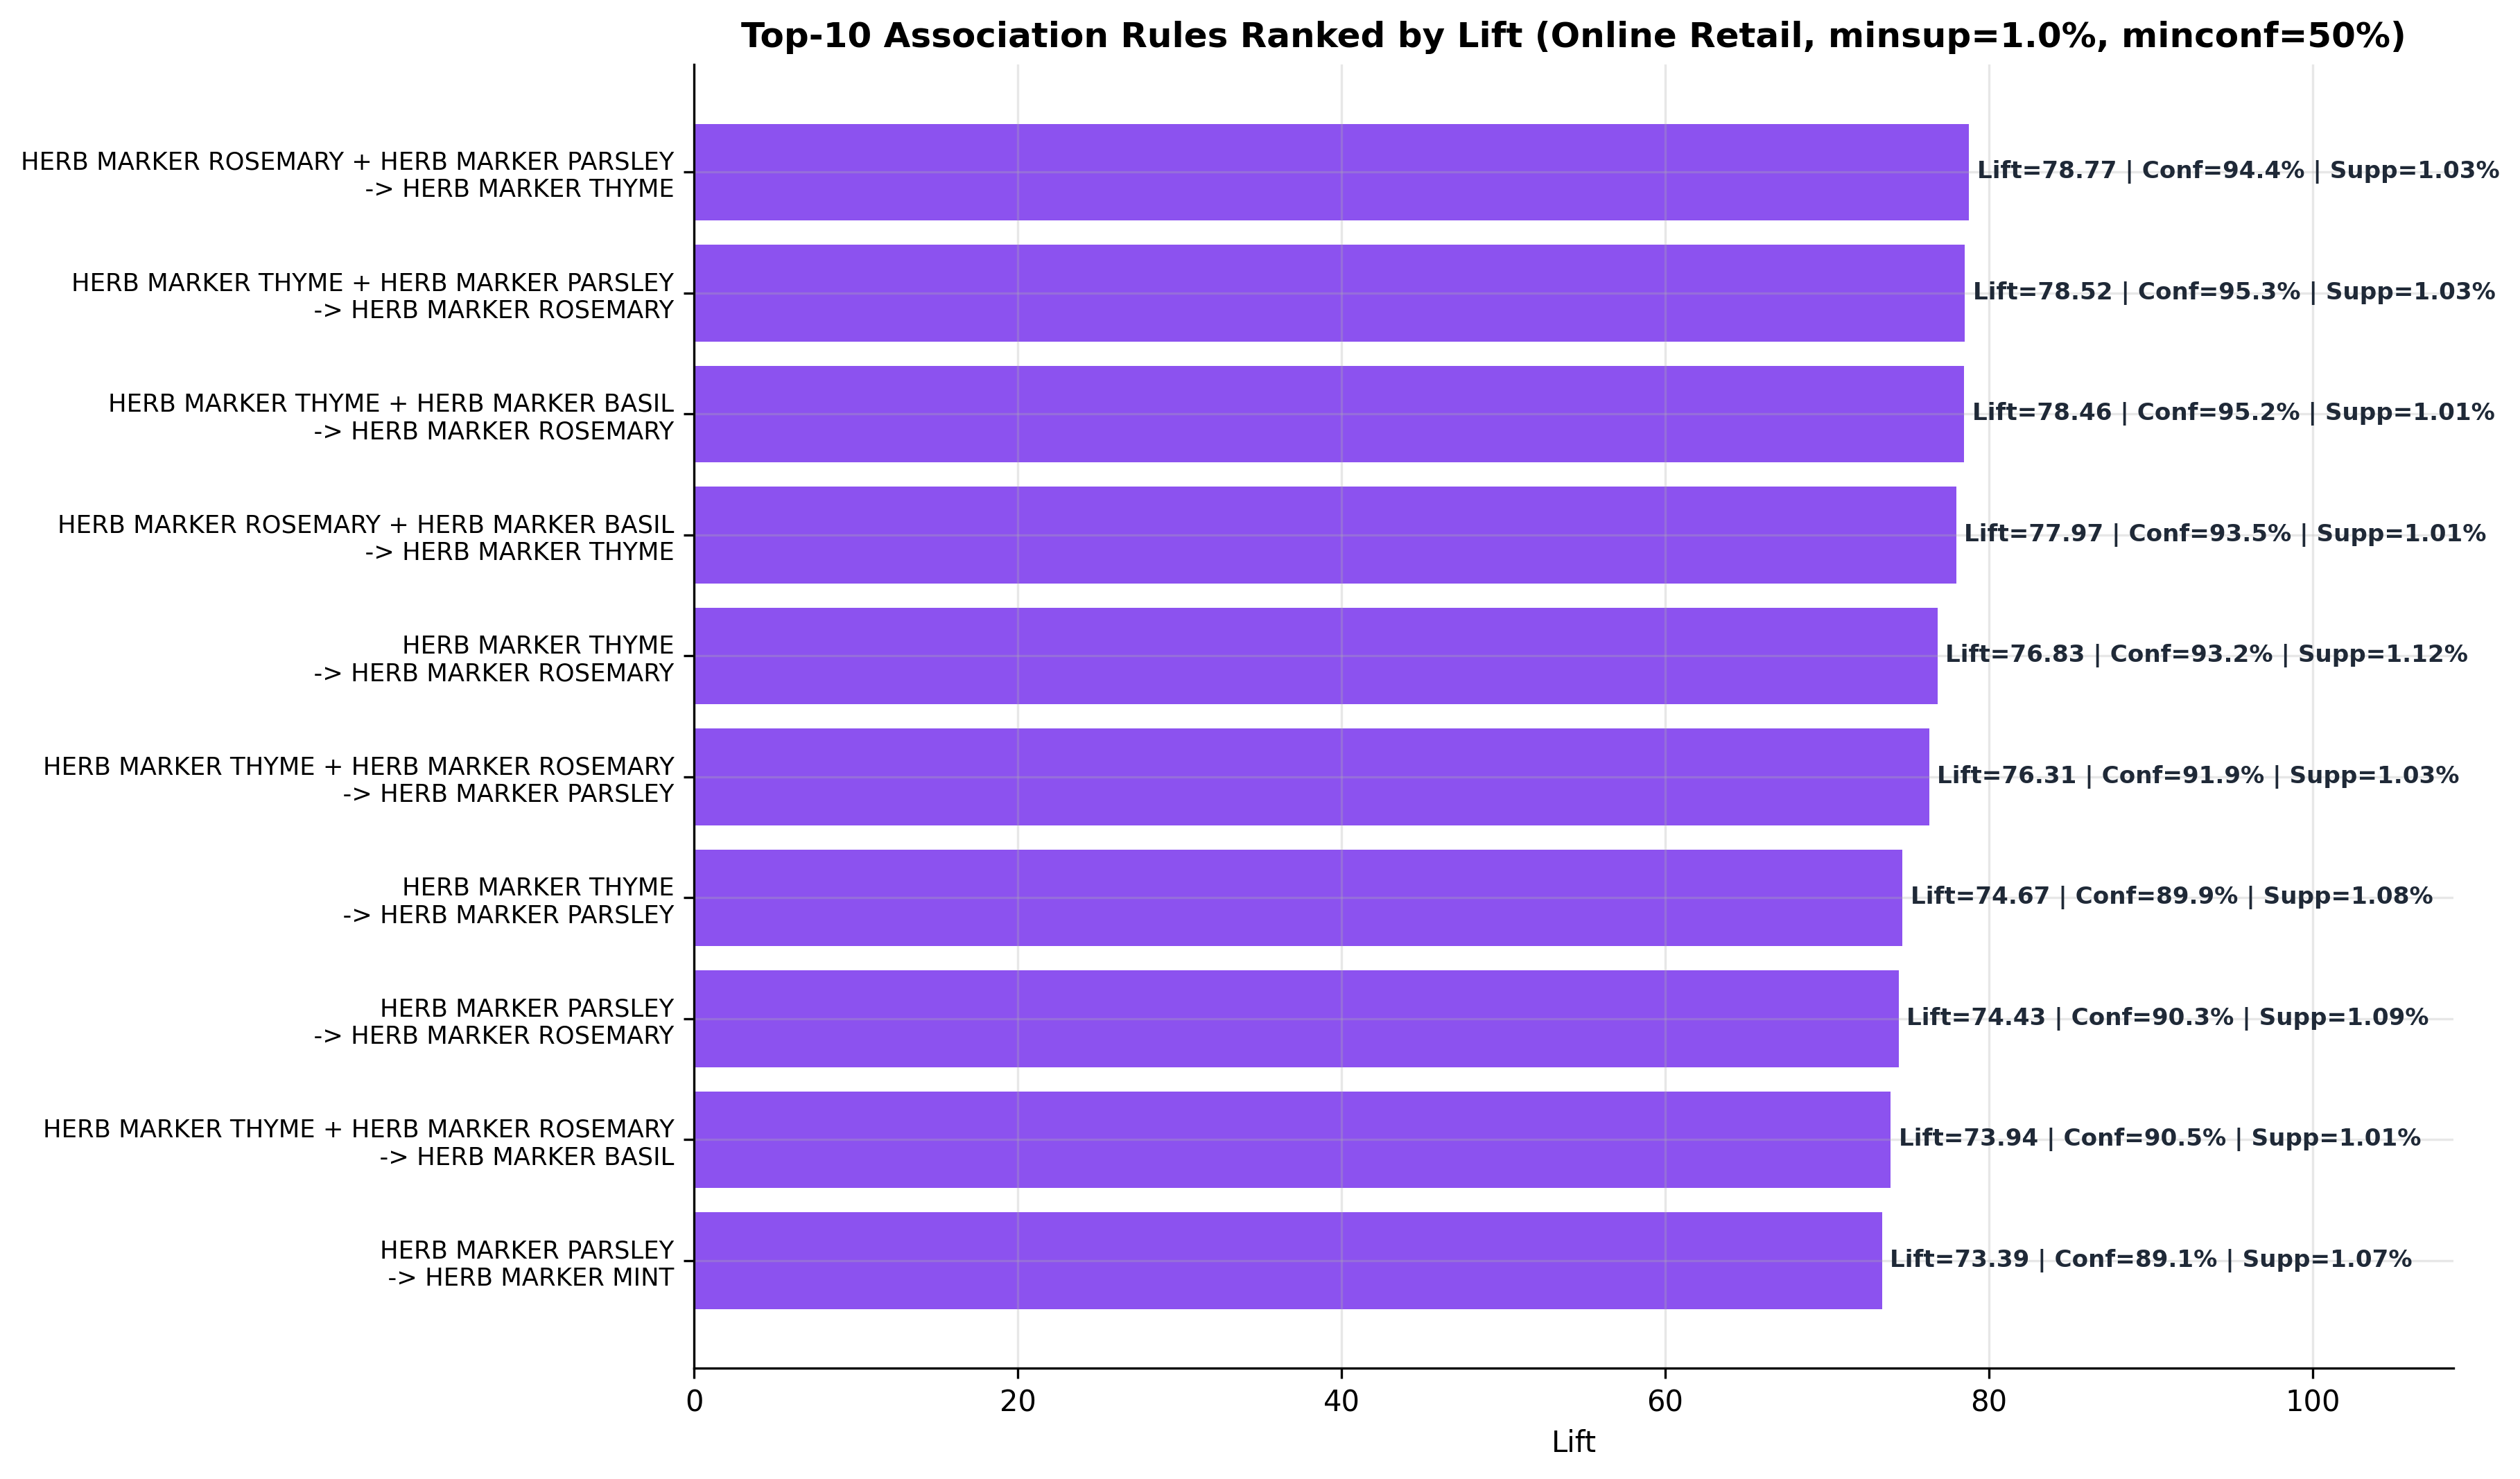

In [13]:
from IPython.display import Image, display as ipy_display

run([sys.executable, "applications/market_basket/plot_mba.py"])

for fig_name in [
    "fig1_top15_products.png",
    "fig2_minsup_sensitivity.png",
    "fig3_rules_scatter.png",
    "fig4_top10_lift.png",
]:
    ipy_display(Image(filename=f"results/app1/figures/{fig_name}"))

#### Kiểm chứng hậu kiểm (Post-hoc Verification)
Tái lập toàn bộ các kiểm tra hậu kiểm: phân bố bộ 6 nhãn **Herb Marker** (gồm `CHIVES`), tỷ lệ nền mùa vụ tháng 10–12/2011 & **Lift tính riêng trong mùa**, và độ đa dạng `CustomerID`.

In [14]:
run([sys.executable, "applications/market_basket/posthoc_analysis.py"])

with open("results/app1/posthoc_verification.json", encoding="utf-8") as f:
    ph = json.load(f)

print("=== 1. Phân bố số nhãn Herb Marker trong 289 hóa đơn có mua dòng này ===")
herb_dist_df = pd.DataFrame([
    {"Số nhãn Herb Marker trong giỏ": int(k), "Số hóa đơn": v,
     "Tỷ lệ trong 289 giỏ Herb (%)": round(100.0 * v / ph["herb_marker_analysis"]["baskets_with_at_least_1_herb"], 2)}
    for k, v in ph["herb_marker_analysis"]["size_distribution_among_herb_baskets"].items()
])
display(herb_dist_df)

print("\n=== 2. Kiểm chứng mức tập trung tháng 10–12/2011 (so với mốc nền sau ngày ra mắt 2011-06-09: 49.70%) ===")
season_df = pd.DataFrame([
    {"Sản phẩm": v["description"], "Ngày bán đầu tiên": v["first_invoice_date"],
     "Mốc nền 10–12/2011 sau ra mắt (%)": v["post_launch_baseline_oct_dec_2011_pct"],
     "HĐ 10–12/2011": v["oct_dec_2011_invoices"], "Tỷ lệ 10–12/2011 (%)": v["oct_dec_2011_pct"]}
    for v in ph["seasonality_analysis"]["wooden_decorations"].values()
])
display(season_df)
print("Lift trong giai đoạn 10–12/2011 (N=5,572):", ph["seasonality_analysis"]["in_season_oct_dec_2011_rules"])
print("Bộ 3 {TREE, STOCKING, SLEIGH}:", ph["seasonality_analysis"]["wooden_3_item_tree_stocking_sleigh"])

print("\n=== 3. Độ đa dạng khách hàng (CustomerID duy nhất) ===")
cust_df = pd.DataFrame([
    {"Cụm sản phẩm": k, "Tổng HĐ": v["invoices"], "HĐ có CustomerID": v["invoices_with_customer_id"], "Khách hàng duy nhất": v["unique_customers"]}
    for k, v in ph["customer_diversity"].items()
])
display(cust_df)

$ /usr/bin/python3 applications/market_basket/posthoc_analysis.py
Saved post-hoc verification to /content/frequent-itemset-mining/results/app1/posthoc_verification.json
{
  "n_total_invoices": 19773,
  "herb_marker_analysis": {
    "per_item": {
      "HERB MARKER THYME": {
        "invoices": 237,
        "support_pct": 1.1986
      },
      "HERB MARKER ROSEMARY": {
        "invoices": 240,
        "support_pct": 1.2138
      },
      "HERB MARKER PARSLEY": {
        "invoices": 238,
        "support_pct": 1.2037
      },
      "HERB MARKER MINT": {
        "invoices": 240,
        "support_pct": 1.2138
      },
      "HERB MARKER BASIL": {
        "invoices": 242,
        "support_pct": 1.2239
      },
      "HERB MARKER CHIVES": {
        "invoices": 209,
        "support_pct": 1.057
      }
    },
    "baskets_with_at_least_1_herb": 289,
    "size_distribution_among_herb_baskets": {
      "1": 18,
      "2": 16,
      "3": 19,
      "4": 38,
      "5": 41,
      "6": 157
    },
  

,Số nhãn Herb Marker trong giỏ,Số hóa đơn,Tỷ lệ trong 289 giỏ Herb (%)
0,1,18,6.23
1,2,16,5.54
2,3,19,6.57
3,4,38,13.15
4,5,41,14.19
5,6,157,54.33



=== 2. Kiểm chứng mức tập trung tháng 10–12/2011 (so với mốc nền sau ngày ra mắt 2011-06-09: 49.70%) ===


,Sản phẩm,Ngày bán đầu tiên,Mốc nền 10–12/2011 sau ra mắt (%),HĐ 10–12/2011,Tỷ lệ 10–12/2011 (%)
0,SET OF 3 WOODEN TREE DECORATIONS,2011-06-09,49.7,217,74.06
1,SET OF 3 WOODEN STOCKING DECORATION,2011-06-09,49.7,237,74.29
2,SET OF 3 WOODEN SLEIGH DECORATIONS,2011-06-09,49.7,228,76.25


Lift trong giai đoạn 10–12/2011 (N=5,572): {'tree_to_stocking': {'in_season_invoices_n': 5572, 'support_count': 172, 'support_pct': 3.09, 'confidence_pct': 79.26, 'lift_in_season': 18.64}, 'sleigh_to_stocking': {'in_season_invoices_n': 5572, 'support_count': 158, 'support_pct': 2.84, 'confidence_pct': 69.3, 'lift_in_season': 16.29}}
Bộ 3 {TREE, STOCKING, SLEIGH}: {'invoices': 159, 'support_pct': 0.8041, 'conf_given_tree_and_stocking_pct': 72.6}

=== 3. Độ đa dạng khách hàng (CustomerID duy nhất) ===


,Cụm sản phẩm,Tổng HĐ,HĐ có CustomerID,Khách hàng duy nhất
0,herb_thyme_rosemary_parsley,203,164,116
1,wooden_tree_stocking,219,182,132
2,dolly_girl_spaceboy_cutlery,228,214,165
3,regency_sugar_milk,243,206,162


#### Diễn giải ý nghĩa kinh doanh & Khuyến nghị thực tiễn

Từ **962 luật kết hợp** khai thác bằng **Optimized CHARM (`CharmMining.jl`)** tại `minsup = 1.0%`, `minconf = 50%` và số liệu hậu kiểm (`posthoc_verification.json`), nhóm rút ra 4 nhận định nhất quán:

1. **Hành vi mua theo bộ sưu tập & bảo vệ biên lợi nhuận:** 6 luật có vế trái 2 nhãn trong Top-10 đạt xác suất mua thêm nhãn thứ 3 là **90.50% – 95.31%** (Lift `73.94 – 78.77`). Trong 289 giỏ mua dòng Herb Marker (6 SKU gồm cả `CHIVES`), **54.3% (`157/289`)** đã mua đủ cả 6 nhãn và **45.7% (`132/289`)** dừng ở 1–5 nhãn. Không nên giảm giá đại trà (gây giảm biên lợi nhuận); ưu tiên nút UX *"Thêm các nhãn còn thiếu"* và gợi ý nhắm riêng vào nhóm 45.7% giỏ chưa đủ bộ.
2. **Liên kết khác công năng trong cùng dòng thiết kế:** `REGENCY SUGAR BOWL GREEN => REGENCY MILK JUG PINK` (tần suất mua kèm lịch sử **75.5%**, Lift `45.36`) và `GARAGE KEY FOB => KEY FOB , SHED` (**71.9%**, Lift `38.24`) phù hợp hiển thị chéo trong mục *"Sản phẩm cùng bộ sưu tập"*.
3. **Cụm trang trí Giáng sinh tập trung ở mức ~1.5× vào tháng 10–12/2011 (một mùa quan sát được):** Cả 3 mã gỗ có ngày bán đầu tiên **2011-06-09**; tỷ lệ hóa đơn tháng 10–12/2011 đạt `74.06% – 76.25%` so với mốc nền sau ra mắt **49.70%** (tính trên toàn bộ hóa đơn cửa hàng từ 2011-06-09, tức gấp `1.49× – 1.53×`, còn ~24–26% diễn ra ở 06–09/2011). Lift tính riêng trong tháng 10–12/2011 là `18.64` và `16.29` (thấp hơn `46.33`/`42.08` do mẫu số 13 tháng gồm cả các tháng ngoài mùa và trước khi mã ra mắt). Bộ 3 `{TREE, STOCKING, SLEIGH}` đạt `159` HĐ (`0.80%`, dưới ngưỡng `1.0%`, `Conf({TREE, STOCKING} => SLEIGH) = 72.60%`). Nhất quán với mục 1: ưu tiên trưng bày theo chủ đề & gợi ý chéo thay vì giảm giá trực tiếp.
4. **Đồng bộ tồn kho & gợi ý chéo cặp đối xứng (*Dolly Girl* & *Spaceboy*):** `CHILDRENS CUTLERY DOLLY GIRL => SPACEBOY` (**76.2%**, Lift `40.97`, 228 HĐ trên **165 khách hàng duy nhất**) gợi ý hiển thị chéo hai mẫu và đồng bộ kế hoạch tồn kho thay vì suy diễn quá mức về nhân khẩu học.

Xem báo cáo chi tiết đầy đủ tại [`docs/app1_market_basket.md`](../docs/app1_market_basket.md).

### 3.2. Ứng dụng 2: Khai thác motif promoter E. coli (UCI Promoter Gene Sequences)

**Tập dữ liệu:** `data/applications/dna/promoters.data` gồm **106 trình tự** (53 promoter `+` / 53 non-promoter `-`), mỗi trình tự dài **57 bp**, căn theo điểm bắt đầu phiên mã từ vị trí `p-50` đến `p7`.

**Biến đổi dữ liệu:** mỗi trình tự là một giao dịch gồm nhãn `class=+` / `class=-` và các **5-mer trượt theo cụm tọa độ** (`C1_xxxxx`, `C2_xxxxx`, `C3_xxxxx`). Các cụm `C1`, `C2`, `C3` được xác định tự động từ hồ sơ thống kê từng vị trí. CHARM khai thác tập phổ biến đóng với `k = 5`, `minsup = 5`.

#### Hồ sơ hóa tọa độ & phân cụm vùng điểm nóng
`cluster.py` tính độ bảo tồn thông tin (IC) và kiểm định chi-bình phương tại từng vị trí `p-50`..`p7`, rồi gom các vị trí có ý nghĩa thống kê (p < 0,05) thành cụm.

In [15]:
run([sys.executable, "applications/dna/cluster.py"])

profile = pd.read_csv("results/app2/promoter_analysis/coordinate_profiling.csv")
display(profile[profile["significant"] == "YES"])

$ /usr/bin/python3 applications/dna/cluster.py
=== HỒ SƠ HÓA THỐNG KÊ TỌA ĐỘ (DATA-DRIVEN PROFILING) ===
Dữ liệu hợp lệ: 106 chuỗi (class=+ : 53 | class=- : 53 | độ dài = 57 bp)

--- CÁC TỌA ĐỘ 'ĐIỂM NÓNG' CÓ Ý NGHĨA THỐNG KÊ (p-value < 0.05) ---
JuliaIdx | BioPos  | IC(+) bits | Base trội (+) | Chi2     | p-value
--------------------------------------------------------------------
6        | p-45    | 0.4294     | a (60.4%)     | 20.7359  | 0.000119
7        | p-44    | 0.2206     | a (49.1%)     | 8.2571   | 0.040987
8        | p-43    | 0.2332     | t (39.6%)     | 10.9838  | 0.011814
9        | p-42    | 0.1916     | t (41.5%)     | 9.5207   | 0.023112
10       | p-41    | 0.2272     | a (49.1%)     | 11.9631  | 0.007511
14       | p-37    | 0.1779     | c (43.4%)     | 8.6997   | 0.033561
15       | p-36    | 1.0830     | t (81.1%)     | 44.6176  | 0.000000
16       | p-35    | 1.0210     | t (81.1%)     | 38.7018  | 0.000000
17       | p-34    | 1.0670     | g (79.2%)     | 39.87

,julia_idx,bio_pos,ic_pos_bits,ic_neg_bits,dom_base_pos,chi2_stat,p_value,significant
5,6,p-45,0.4294,0.0273,a (60.4%),20.7359,0.000119,YES
6,7,p-44,0.2206,0.0297,a (49.1%),8.2571,0.040987,YES
7,8,p-43,0.2332,0.0092,t (39.6%),10.9838,0.011814,YES
8,9,p-42,0.1916,0.0198,t (41.5%),9.5207,0.023112,YES
9,10,p-41,0.2272,0.0180,a (49.1%),11.9631,0.007511,YES
13,14,p-37,0.1779,0.0313,c (43.4%),8.6997,0.033561,YES
14,15,p-36,1.0830,0.0974,t (81.1%),44.6176,0.000000,YES
15,16,p-35,1.0210,0.0569,t (81.1%),38.7018,0.000000,YES
16,17,p-34,1.0670,0.0337,g (79.2%),39.8702,0.000000,YES
17,18,p-33,0.4375,0.0783,a (52.8%),22.8098,0.000044,YES


#### Khai thác tập đóng bằng Optimized CHARM
`run_dna.jl` mã hóa giao dịch (`class=±` + 5-mer theo cụm) rồi chạy `to_vertical_bit` + `run_charm_bit` của `CharmMining.jl` (Chương 1) với `minsup = 5`.

In [16]:
run(["julia", "--project=.", "applications/dna/run_dna.jl"])

$ julia --project=. applications/dna/run_dna.jl
=== E. coli De Novo Promoter Mining (CharmBit | k=5) ===
Records=106 | skipped=0 | clusters=3 | minsup=5
Total Closed Patterns = 154 | class=+ patterns = 52 | class=- patterns = 27
Results written to /content/frequent-itemset-mining/results/app2/promoters_charm_output.txt


#### Lọc tương phản & phân tích pattern đặc trưng cho promoter
`report.py` đối chiếu các tập đóng với 106 chuỗi gốc để tính Confidence, Lift, Growth Rate và kiểm định chi-bình phương, ghép các 5-mer chồng lấp thành chuỗi đồng thuận và đo khoảng cách giữa các cụm.

In [17]:
run([sys.executable, "applications/dna/report.py"])

out_dir = Path("results/app2/promoter_analysis")
disc_path = out_dir / "discriminative_promoters.csv"
if disc_path.exists():
    disc = pd.read_csv(disc_path)
    print(f"Số mẫu phân biệt đạt chuẩn: {len(disc)}")
    display(disc.head(15))

all_motifs = pd.read_csv(out_dir / "all_closed_motifs.csv")
print("\nPhạm vi pattern (Intra vs Cross cluster):")
display(all_motifs["pattern_scope"].value_counts())
print("Đạt bộ lọc phân biệt (discriminative_pass):")
display(all_motifs["discriminative_pass"].value_counts())

$ /usr/bin/python3 applications/dna/report.py
=== TỔNG HỢP TRI THỨC TỪ TẬP ĐÓNG TƯƠNG PHẢN ===
Tổng số tổ hợp motif duy nhất đánh giá : 128
Số mẫu đạt chuẩn phân biệt (Conf>=0.85, GR>=3.0, p<0.05): 40

--- 1. TOP CHUỖI ĐỒNG THUẬN (CONSENSUS ASSEMBLY) ĐẶC TRƯNG CHO PROMOTER (+) ---
[Intra_Cluster] Sup(+/-)= 5/ 0 | Conf=1.00 | Lift=2.00x | GR=Inf  | p=0.0220 | AT=60.0% | C3:cctataatgcgcc
[Intra_Cluster] Sup(+/-)= 6/ 0 | Conf=1.00 | Lift=2.00x | GR=Inf  | p=0.0117 | AT=50.0% | C3:ataatgcgcc
[Intra_Cluster] Sup(+/-)= 6/ 0 | Conf=1.00 | Lift=2.00x | GR=Inf  | p=0.0117 | AT=66.7% | C3:tataatgcgc
[Intra_Cluster] Sup(+/-)= 7/ 0 | Conf=1.00 | Lift=2.00x | GR=Inf  | p=0.0062 | AT=60.0% | C3:ataatgcgc
[Intra_Cluster] Sup(+/-)= 6/ 0 | Conf=1.00 | Lift=2.00x | GR=Inf  | p=0.0117 | AT=68.0% | C3:tataatgcgcc
[Intra_Cluster] Sup(+/-)= 7/ 0 | Conf=1.00 | Lift=2.00x | GR=Inf  | p=0.0062 | AT=60.0% | C3:ataatgcgcc
[Intra_Cluster] Sup(+/-)= 7/ 0 | Conf=1.00 | Lift=2.00x | GR=Inf  | p=0.0062 | AT=85.0% | C

,consensus_motifs,raw_items,num_items,clusters_involved,pattern_scope,sup_pos,sup_neg,confidence_pos,lift_pos,growth_rate,chi2_stat,p_value,mean_span_bp,at_content_pct,discriminative_pass
0,C3:cctataatgcgcc,C3_aatgc C3_ataat C3_atgcg C3_cctat C3_ctata C...,9,C3,Intra_Cluster,5,0,1.0,2.0,inf,5.2475,0.021978,8.0,60.0,YES
1,C3:ataatgcgcc,C3_aatgc C3_ataat C3_atgcg C3_gcgcc C3_taatg C...,6,C3,Intra_Cluster,6,0,1.0,2.0,inf,6.3600,0.011672,5.0,50.0,YES
2,C3:tataatgcgc,C3_aatgc C3_ataat C3_atgcg C3_taatg C3_tataa C...,6,C3,Intra_Cluster,6,0,1.0,2.0,inf,6.3600,0.011672,5.0,66.7,YES
3,C3:ataatgcgc,C3_aatgc C3_ataat C3_atgcg C3_taatg C3_tgcgc,5,C3,Intra_Cluster,7,0,1.0,2.0,inf,7.4949,0.006187,4.0,60.0,YES
4,C3:tataatgcgcc,C3_aatgc C3_ataat C3_gcgcc C3_taatg C3_tataa,5,C3,Intra_Cluster,6,0,1.0,2.0,inf,6.3600,0.011672,6.5,68.0,YES
5,C3:ataatgcgcc,C3_aatgc C3_ataat C3_gcgcc C3_taatg,4,C3,Intra_Cluster,7,0,1.0,2.0,inf,7.4949,0.006187,5.4,60.0,YES
6,C3:tataatgc,C3_aatgc C3_ataat C3_taatg C3_tataa,4,C3,Intra_Cluster,7,0,1.0,2.0,inf,7.4949,0.006187,3.0,85.0,YES
7,C3:aatgcgcc,C3_aatgc C3_atgcg C3_gcgcc C3_tgcgc,4,C3,Intra_Cluster,7,0,1.0,2.0,inf,7.4949,0.006187,3.0,30.0,YES
8,C3:aatgcgc,C3_aatgc C3_atgcg C3_tgcgc,3,C3,Intra_Cluster,9,0,1.0,2.0,inf,9.8351,0.001712,2.0,40.0,YES
9,C3:ataatgc,C3_aatgc C3_ataat C3_taatg,3,C3,Intra_Cluster,8,0,1.0,2.0,inf,8.6531,0.003265,2.0,80.0,YES



Phạm vi pattern (Intra vs Cross cluster):


,count
pattern_scope,
Intra_Cluster,125
Cross_Cluster,3


Đạt bộ lọc phân biệt (discriminative_pass):


,count
discriminative_pass,
NO,88
YES,40


Diễn giải chi tiết (hộp `-10` TATAAT, liên kết xuyên cụm `C1`–`C3`, giới hạn của cách mã hóa k-mer) xem tại
[`docs/dna.md`](../docs/dna.md).

---
**Hoàn tất.** Toàn bộ kết quả được sinh lại trong `results/` (Chương 1, 3) và `comparison/` (Chương 2).